<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/04_Botnet_DGA_Detection/QHTC_BotnetDGA_Tehrani2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QHTC for DGA-botnet detection: Tehrani et al. (2024) and its 2026 Author Correction, step by step

This notebook re-implements, runs and checks the experiments of

> Madjid G. Tehrani, Eldar Sultanow, William J. Buchanan, Malik Amir, Anja Jeschke, Mahkame Houmani, Raymond Chow and
> Mouad Lemoudden, "Stabilized quantum-enhanced SIEM architecture and speed-up through Hoeffding tree algorithms enable
> quantum cybersecurity analytics in botnet detection", *Scientific Reports* 14, 1732 (2024).
> https://doi.org/10.1038/s41598-024-51941-8

**Two code bases are used, and both are credited here.**

1. **The authors' experiment code of the paper** (all seven notebooks in the `azure/` folder: `Paper01`/`Paper02` QHTC,
   `Paper03` SamplerQNN, `Paper04` EstimatorQNN, `Paper05` VQC, `Paper06` PegasosQSVC, `Paper07` QSVC):
   https://github.com/Sultanow/quantum-botnet-detection (pinned commit `c862794`). The notebook downloads those files, runs the
   authors' own Hoeffding-tree class from `Paper02` next to its re-implementation, and sets the settings of the five hybrid
   quantum binary classifiers (feature map, ansatz, optimiser, split, scaling) to what those notebooks do.
2. **The 2026 Author Correction and its corrected QHTC code**, published by the authors at
   https://github.com/owlmt/quantumHTC-repo (folder `author_correction_2026`, pinned commit `ed83637`; the repository owner is
   one of the paper's authors, who asked for this repository to be used as the corrected reference). The correction replaces the
   `ZFeatureMap`-plus-trace-distance "quantum walk" of the paper's Algorithm 3 by a 7-qubit IQP encoding (14 Pauli expectations),
   feeds it to `river`'s `HoeffdingTreeClassifier` and evaluates on a locked, hash-recorded held-out set of 100 rows instead of
   the paper's batch loop. The notebook downloads that code at the pinned commit, **checks every file against a pinned SHA-256**,
   and runs the correction's own functions unchanged (see section 5).

**What the notebook does.** It downloads the paper's two samples of the IEEE *Botnet DGA Dataset* (1000 and 5000 domain
names, seven engineered features each), reproduces the paper's original Table 6 with the authors' original tree code and shows
why those numbers come out as they do, then runs the **corrected QHTC** of the Author Correction (paper batch protocol,
leakage-free prequential protocol, and the correction's locked held-out protocol with litmus control) next to a classical
Hoeffding tree on the raw features, and finally trains the paper's five hybrid quantum binary classifiers (VQC, QSVC,
PegasosQSVC, SamplerQNN, EstimatorQNN; Table 5, Aer rows) with the settings of the authors' `azure/` notebooks, with classical
baselines on identical inputs and a claim-by-claim comparison.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
pinned Qiskit versions and `river`; if Colab asks to restart the session, restart and run all again. Nothing needs a GPU, an
IBM Quantum account or Azure Quantum credits: the paper's real-device rows (Table 4) and cloud-emulator rows cannot be rerun
here and are marked as such. The two GitHub repositories and the two Azure blobs must be reachable from the runtime.

**Runtime.** `FAST_MODE = True` (3 batches, 1500 rows and one IQP architecture for the corrected QHTC, 300 domain names and 20 optimiser iterations) took 16 (28 when the machine was shared with other jobs) minutes on the shared 4-core laptop used for validation, about a third of it the correction's own encoder; the corrected-QHTC numbers of that mode are not meaningful (1400 development rows only). `FAST_MODE = False` took 95 minutes on the same, heavily loaded machine (33 minutes for the two corrected-QHTC encodings, 24 minutes for the two VQC fits, 13 minutes for the kernel methods (mostly the 1024-shot Pegasos kernel), 11 minutes for the QNNs); on an idle machine expect roughly a third of that. The committed outputs are from the full run. The optimiser budgets of the variational models (60 COBYLA evaluations for each VQC, 20 SPSA iterations on 150 rows for the QNNs on botnet rows) are far below the authors' defaults (COBYLA() = 1000, SPSA() = 100) because a statevector simulator on a CPU cannot afford 1000 evaluations of 700 circuits; set `AZURE_BUDGET = True` to use the authors' budgets if you have several hours.

**What you get at the end.** A table with every number of the paper's Tables 5 and 6 and of the Author Correction's replacement
Table 6 next to the value this notebook obtains, a verdict per claim, and a critical reading that states what the correction
changes and what it does not.

## The paper in one page

**Problem.** Botnets locate their command-and-control servers through *domain generation algorithms* (DGA): the malware
computes thousands of pseudo-random domain names per day and the operator registers one of them. A SIEM that can tell a
DGA name (`xkqzvhtr.net`) from a legitimate one (`wikipedia.org`) from DNS telemetry can block the whole botnet. The paper
treats this as binary classification of seven numbers computed from each domain name.

**Decision.** For every domain name, benign (class 0) or DGA (class 1).

**Data.** The IEEE *Botnet DGA Dataset* (Suryotrisongko, 2020; DOI 10.21227/rg6z-z622): 1,803,333 names from the Alexa
top-1M list and ten DGA families, with seven engineered features: `CharLength`, `Entropy` (Shannon entropy of the
characters), `REAlexa` (Kullback-Leibler divergence to the Alexa character distribution), `MinREBotnets` (minimum KL
divergence to the ten DGA families), `InformationRadius` (Jensen-Shannon divergence to the families), `TreeNewFeature`
(the output of a decision tree trained on four of the other features) and `nGramReputation_Alexa` (an n-gram reputation
score). The paper draws fixed random samples: 1000 rows for the five known classifiers (as in its reference [12]), 5000
rows for QHTC, 100 rows for real devices. Both sample files are published with the code and are used here unchanged. The
sample files contain only the binary label, not the DGA family, so no multiclass labels exist to plot.

**Method.** Five known hybrid quantum binary classifiers (HQBC) from `qiskit-machine-learning` with a 7-qubit
`ZFeatureMap`, the `RealAmplitudes` ansatz and COBYLA/SPSA (or Pegasos' SGD) are run on the Aer simulator, on three
real-device emulators (IonQ, Rigetti, Quantinuum via Azure Quantum) and on the three real devices. The new model, QHTC,
maps each feature row to a 7-qubit `ZFeatureMap` state, computes the reduced density matrix of every qubit and sums the
trace distances between neighbouring qubits around the cycle 0-1-2-...-6-0 ("quantum walk"), then feeds that number to
an incremental Hoeffding tree (Algorithms 1-3) trained batch-wise on five batches of 1000 rows.

**The 2026 Author Correction** (Sci. Rep. 14:1732, Author Correction) amends the QHTC claims only: the 91.2 % average
accuracy and the 100 % final batches (abstract, contribution 1, Table 5 row "QHTC-Rigetti-S", Table 6, the "Performance
metrics of QHTC" subsection) are replaced by a held-out accuracy of 0.897 +/- 0.013 for a depth-1, linear-entanglement IQP
encoding, and Algorithm 3 is replaced accordingly. Tables 2 and 4, Algorithms 1 and 2 and all comparator rows of Table 5 are
declared unaffected.

**Claims checked here** (Tables 5 and 6; everything on the Aer simulator or the Rigetti emulator):

| Claim | Source | Value |
|---|---|---|
| QHTC, 5000 samples: accuracy / F1 / AUC per batch | paper Table 6 | 57.1/4.5/51.1, 99.0/98.8/98.9, 100/100/100, 100/100/100, 100/100/100 |
| QHTC average accuracy / F1 / AUC | paper Table 6 | 91.2 % / 80.7 % / 90.0 % ; "100 % already after three of five batches" |
| QHTC total execution time (Rigetti emulator) | paper Table 5 | 1687 s, "two orders of magnitude" below the other HQBCs |
| QHTC held-out accuracy, IQP_d1_linear | Author Correction, replacement Table 6 | 0.897 +/- 0.013 (litmus 0.460, p_BH 0.035) |
| Classical Hoeffding tree on the raw 7 features, held-out | Author Correction | 0.840 +/- 0.000 (litmus 0.510) |
| Other 11 pre-registered architectures | Author Correction | 0.783 to 0.887, verdicts CONFIRMED_WIN / borderline / lose |
| VQC-Aer (COBYLA), 1000 samples | paper Table 5 | 54 % (ref. [12] reports 76.8 % with the same setting) |
| PegasosQSVC-Aer, 1000 samples | paper Table 5 | 90 %, 45 s |
| QSVC-Aer, 1000 samples | paper Table 5 | 87 %, 3091 s |
| SamplerQNN-Aer, 1000 samples | paper Table 5 | 76 %, 374 s |
| EstimatorQNN-Aer, 1000 samples | paper Table 5 | 84 %, 410 s |
| Real devices (Table 4), 100 samples | paper Table 4 | 39-59 % ; cannot be rerun without Azure Quantum access |

### What follows the paper and what had to be chosen

| Item | Paper / authors' code | This notebook |
|---|---|---|
| Data files | `BotnetDgaDataset_1000.csv`, `BotnetDgaDataset_5000_newMethod.csv` from the authors' Azure blobs; the correction ships `BotnetDgaDataset_5000.csv` (no header line) | Azure URLs, cached in `DATA_DIR`; the correction's CSV is downloaded too and asserted to hold the same values; if the 1000-row blob is gone, the first 1000 rows of the 5000-row file are used (`# CHOICE`) |
| Positive class | header of the 1000-row file: `benign, dga` = 0, 1 | DGA = 1 is the positive class in every metric |
| QHTC, original (Algorithm 3) | `StandardScaler` on all 5000 rows; `ZFeatureMap` walk; authors' `HoeffdingTreeClassifier` (delta 0.01, tie 0.05); batch k tested after `partial_fit` on every other batch | identical; the authors' class is also executed from the downloaded `Paper02` notebook and compared prediction by prediction |
| QHTC, corrected (Author Correction) | `MinMaxScaler` to [0,1]; `IQP_d1_linear` (and 11 other architectures); 14 features (7 Z + 7 X expectations); `river` tree `grace_period=50, delta=1e-7, tau=0.05`; locked 100-row held-out (seed 42), litmus labels (seed 1234), seeds 0-2, BH-FDR | the correction's own functions, unmodified, executed from the pinned file (SHA-256 checked); architectures run: `CORR_ARCHS` (the Q-kernel-projection family is not rerun, its published rows are shown) |
| Backend of the corrected QHTC | `AerSimulator(method="statevector")`, qiskit 1.2.4, qiskit-aer 0.15.1, river 0.21.2 | the same call with qiskit 2.5.2, qiskit-aer 0.17.2, river 0.26.1 (library versions differ; see the verdicts) |
| Split for VQC | `train_test_split(train_size=700, test_size=300, random_state=7)`, class-sorted points, labels benign=+1 / dga=-1, **no scaling** (`Paper05`) | identical |
| Split and scaling for QSVC / Pegasos | `MinMaxScaler((0, pi))` fitted on **all 1000 rows**, `train_test_split(train_size=700, shuffle=False)` (`Paper06`, `Paper07`) | identical (the authors' protocol); an extra run with the scaler fitted on the training rows only is added (`# CHOICE`) |
| Feature map / ansatz | `ZFeatureMap(7, reps=1)`; VQC: `RealAmplitudes(7, reps=1, entanglement="pairwise")`; QNN notebooks: `ZZFeatureMap(7)` + `RealAmplitudes(7, reps=1)` (Sampler) / `RealAmplitudes(7)` (Estimator, 3 reps) | identical |
| Optimiser | VQC: `COBYLA()` (default maxiter 1000); QNNs: `SPSA()` (maxiter 100); Pegasos C = 1000, `num_steps` = 100; QSVC default C | the same optimisers; iteration budgets lowered (`# CHOICE`, cost: `VQC_MAXITER`, `SPSA_MAXITER_BOTNET`), authors' budgets with `AZURE_BUDGET = True` |
| VQC implementations in `Paper05` | the library `VQC` (cells 12-14) and a hand-written loop with full bit-string parity, cross-entropy summed over the training points, `COBYLA()`, 1024 shots (cells 17-19) | both are run |
| Simulator | `BasicAer`/Aer `qasm_simulator`, 1024 shots (VQC, Pegasos kernel); statevector kernel for QSVC; library-default primitives for the QNNs | Aer `SamplerV2`/`EstimatorV2`, 1024 shots, seeded (VQC, Pegasos kernel with `ComputeUncompute`, both QNNs; `# CHOICE`: the default pure-Python primitives are 5-10 times slower); `FidelityStatevectorKernel` for QSVC |
| QNN training data | the botnet CSV is loaded and then **overwritten by 50 random synthetic points**, scored on the training set (`Paper03`, `Paper04`) | that code path is replayed exactly; the QNNs are also trained on the botnet split (first `QNN_TRAIN_ROWS` rows, `# CHOICE`) |
| Seeds | `algorithm_globals.random_seed = 12345` (kernels), 42 (QNN), none elsewhere | `SEED = 42` everywhere |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning / river is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("river") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "river==0.26.1" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning and river already present; skipping pip install.")

qiskit-machine-learning and river already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: reduced demo in about 10-15 minutes. False: the full run (see the Runtime note above).
SEED      = 42              # CHOICE: the paper seeds only its kernels (12345) and QNNs (42)

N_FEATURES = 7              # the seven engineered features of the IEEE Botnet DGA Dataset
N_QUBITS   = 7              # one qubit per feature
BATCH_SIZE = 1000           # paper: five batches of 1000 rows for QHTC
AZURE_BUDGET = False        # True: the authors' optimiser budgets (COBYLA() = 1000 evaluations, SPSA() = 100 iterations); hours of CPU time

if FAST_MODE:
    N_QHTC_ROWS   = 3000    # original QHTC: three batches instead of five
    N_WALK_QISKIT = 200     # rows whose quantum walk is simulated with Qiskit (closed form for the rest)
    CORR_ROWS     = 1500    # corrected QHTC: first 1500 of the 5001 rows (the locked held-out set then differs from the published one)
    CORR_ARCHS    = ["IQP_d1_linear"]
    ENCODE_WORKERS = 2
    N_HQBC        = 300     # rows of the 1000-sample file used for the five other classifiers
    TRAIN_SIZE    = 210     # 70 % / 30 % as in the paper's 700 / 300
    VQC_MAXITER, VQC_HAND_MAXITER, SPSA_MAXITER_BOTNET, QNN_TRAIN_ROWS = 20, 20, 8, 120
    N_SEEDS       = 2       # repeated shuffled splits for the cheap models (mean +- std)
else:
    N_QHTC_ROWS   = None    # all 5001 rows of the file (five batches + one leftover row)
    N_WALK_QISKIT = None    # every row through Qiskit
    CORR_ROWS     = None    # all 5001 rows, locked held-out identical to the published one
    CORR_ARCHS    = ['IQP_d1_linear', 'IQP_d1_alltoall']
    ENCODE_WORKERS = 4
    N_HQBC        = 1000    # the whole 1000-sample file
    TRAIN_SIZE    = 700     # paper: train_size=700, test 300
    VQC_MAXITER, VQC_HAND_MAXITER, SPSA_MAXITER_BOTNET, QNN_TRAIN_ROWS = 60, 60, 20, 150   # CHOICE: far below the authors' defaults, cost control
    N_SEEDS       = 3
if AZURE_BUDGET:
    VQC_MAXITER, VQC_HAND_MAXITER, SPSA_MAXITER_BOTNET, QNN_TRAIN_ROWS = 1000, 1000, 100, TRAIN_SIZE

SHOTS          = 1024       # authors' code: shots=1024 on the qasm simulator
PEGASOS_C      = 1000       # authors' code (Paper06): C = 1000
PEGASOS_STEPS  = 100        # authors' code (Paper06): tau = 100
AZ_SPLIT_SEED  = 7          # authors' code (Paper05): train_test_split(..., random_state=7)
SPSA_MAXITER_TOY = 12 if FAST_MODE else 100      # authors' code (Paper03/04): SPSA() default maxiter = 100 (FAST_MODE: 12)

HT_DELTA, HT_TAU = 0.01, 0.05   # original paper's Hoeffding tree: delta=0.01, tie_threshold=0.05
HT_GRACE_PERIOD  = 50           # CHOICE: river's grace period for the leakage-free runs of the original walk (the paper's code splits after every row)

DATA_DIR  = "data"
URL_5000  = "https://dgadata.blob.core.windows.net/dga/BotnetDgaDataset_5000_newMethod.csv"              # Paper02_QHTC_AER_Simulator.ipynb
URL_1000  = "https://aq5efd7d2644dd406cb3ec2d.blob.core.windows.net/dga/BotnetDgaDataset_1000.csv"       # Paper03..07 notebooks
IBM_TOKEN = ""              # not used: nothing in this notebook runs on hardware

In [3]:
import os, time, warnings, json, ast, hashlib, io, math, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import clear_output, display
from scipy.stats import skew, kurtosis, ttest_1samp, binomtest

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit.library import z_feature_map, zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace
from qiskit_aer.primitives import SamplerV2 as AerSampler, EstimatorV2 as AerEstimator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel, FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.algorithms import QSVC, PegasosQSVC, VQC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA, SPSA
from qiskit_machine_learning.utils import algorithm_globals

import river
from river import tree as river_tree

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T_NOTEBOOK_START = time.perf_counter()

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("river", river.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| original QHTC rows:", N_QHTC_ROWS or "all", "| corrected QHTC rows:", CORR_ROWS or "all", "| architectures:", CORR_ARCHS,
      "| HQBC rows:", N_HQBC, "| VQC maxiter", VQC_MAXITER, "/", VQC_HAND_MAXITER, "| SPSA maxiter (botnet)", SPSA_MAXITER_BOTNET)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
river 0.26.1 | numpy 2.5.4 | pandas 3.0.6
scikit-learn 1.9.1
FAST_MODE = False | original QHTC rows: all | corrected QHTC rows: all | architectures: ['IQP_d1_linear', 'IQP_d1_alltoall'] | HQBC rows: 1000 | VQC maxiter 60 / 60 | SPSA maxiter (botnet) 20


## 1. Data and the two code bases

The full dataset (1.8 million names, 205 MB) sits behind an IEEE DataPort login, but the authors host the two fixed random
samples their experiments use on public Azure storage containers: `BotnetDgaDataset_1000.csv` (1000 rows, used by VQC, QSVC,
PegasosQSVC, SamplerQNN and EstimatorQNN) and `BotnetDgaDataset_5000_newMethod.csv` (5001 rows, used by QHTC). Both are
fetched below. The 1000-row file carries a scikit-learn style header line (`1000,7,benign,dga`), which says that class 0 is
*benign* and class 1 is *DGA*; the 5000-row file has a normal header. Column names follow the IEEE DataPort listing; the
paper's Table 2 calls `Entropy` "EntropyValue", `REAlexa` "RelativeEntropy" and `nGramReputation_Alexa` "Reputation".

Then the two GitHub repositories are used. Every file is downloaded **at a pinned commit** and its SHA-256 is compared with the
value recorded when this notebook was written; a mismatch stops the notebook, so the code that is run is provably the code that
is credited.

In [4]:
COLS     = ["Entropy", "REAlexa", "MinREBotnets", "InformationRadius", "CharLength", "TreeNewFeature", "nGramReputation_Alexa", "Result"]
FEATURES = COLS[:-1]
CLASS_NAMES = ["benign (0)", "dga (1)"]

def fetch(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=120); r.raise_for_status()
        open(path, "wb").write(r.content)
        print("downloaded", os.path.basename(path), f"({len(r.content)/1e3:.0f} kB)")
    else:
        print("using cached", path)
    return path

def load_5000():
    path = os.path.join(DATA_DIR, "BotnetDgaDataset_5000_newMethod.csv")
    try:
        fetch(URL_5000, path)
    except Exception as e:
        raise RuntimeError(f"could not download the 5000-row file ({type(e).__name__}); place it in {DATA_DIR}/ (see the IEEE DataPort link above)")
    df = pd.read_csv(path, encoding="utf-8-sig")          # the file starts with a byte-order mark
    df.columns = COLS
    return df

def load_1000(df5000):
    path = os.path.join(DATA_DIR, "BotnetDgaDataset_1000.csv")
    try:
        fetch(URL_1000, path)
        return pd.read_csv(path, header=None, skiprows=1, names=COLS)   # first line is "1000,7,benign,dga,,,,"
    except Exception as e:
        print(f"1000-row blob unavailable ({type(e).__name__}); # CHOICE: using the first 1000 rows of the 5000-row file instead")
        return df5000.iloc[:1000].reset_index(drop=True)

t0 = time.time()
df5000 = load_5000()
df1000 = load_1000(df5000)
print(f"loaded in {time.time()-t0:.1f} s: 5000-file {df5000.shape}, 1000-file {df1000.shape}")
for name, d in [("5000-file", df5000), ("1000-file", df1000)]:
    vc = d["Result"].value_counts().sort_index()
    print(f"{name}: benign {vc.get(0, 0)}, dga {vc.get(1, 0)} ({100*d['Result'].mean():.1f} % DGA), "
          f"missing values {int(d.isnull().sum().sum())}, duplicate rows {int(d.duplicated().sum())}")
overlap = len(df1000.merge(df5000.drop_duplicates(), how="inner"))
print(f"rows shared by the two files: {overlap} (they are different random samples of the 1.8 M names)")
df5000.head()

using cached data\BotnetDgaDataset_5000_newMethod.csv
using cached data\BotnetDgaDataset_1000.csv
loaded in 0.1 s: 5000-file (5001, 8), 1000-file (1000, 8)
5000-file: benign 2763, dga 2238 (44.8 % DGA), missing values 0, duplicate rows 31
1000-file: benign 551, dga 449 (44.9 % DGA), missing values 0, duplicate rows 1
rows shared by the two files: 15 (they are different random samples of the 1.8 M names)


,Entropy,REAlexa,MinREBotnets,InformationRadius,CharLength,TreeNewFeature,nGramReputation_Alexa,Result
0,3.013071,1.055617,0.889698,0.628782,21,0.107095,152.009430,0
1,3.546594,0.786072,0.805445,0.520243,17,0.367645,133.570536,0
2,3.202820,1.302522,0.479128,0.590865,20,0.967923,61.759207,1
3,3.121654,0.934857,0.656545,0.599781,28,0.487624,184.481562,1
4,3.558519,0.702511,0.586947,0.499722,25,0.667705,138.302631,0


In [5]:
# ---- the two GitHub repositories, pinned commits, pinned SHA-256 ----
REPO_COMMIT  = "ed83637a152c161adfbcb87521267f17a436dddc"      # owlmt/quantumHTC-repo (2026 Author Correction)
AZURE_COMMIT = "c862794d7a9e4bbdf212a1eaafc7be9d86df3b55"      # Sultanow/quantum-botnet-detection (the paper's code)
RAW_CORR  = f"https://raw.githubusercontent.com/owlmt/quantumHTC-repo/{REPO_COMMIT}/"
RAW_AZURE = f"https://raw.githubusercontent.com/Sultanow/quantum-botnet-detection/{AZURE_COMMIT}/"
EXP = "author_correction_2026/experiment_design/"
PINNED = {   # path -> SHA-256 of the file as served by raw.githubusercontent.com at the pinned commit
    RAW_CORR + EXP + "streaming_regime/streaming_iqp.py":  "df9e316ecea5791f026b16023b7776451cbcf186b5db797f0b59a41145cc1603",
    RAW_CORR + EXP + "corrigendum_runner.py":              "e82cfbc5c357e31873b0b62998b84c951b762f1ae2a59b25346eedd10d0385be",
    RAW_CORR + "author_correction_2026/data/BotnetDgaDataset_5000.csv":   "49422a7096d898a26fadd59e2d52b92ced11ad1fdd636da2b91b5b264a03b3b4",
    RAW_CORR + "author_correction_2026/data/heldout_indices.json":        "d8a68fd6996dc75fc458c59a6b8489b51e998e0373ee1c62cc59c251bb70b571",
    RAW_CORR + "author_correction_2026/results/streaming_results.csv":    "acd7ab5ac9b909cfb450577692f9904f4fefe75dec6f7b9ed66310533e1d33ef",
    RAW_AZURE + "azure/Paper02_QHTC_AER_Simulator.ipynb":  "25e858ae667c87e31259b314979c88a473c2f75f17edf8b91ee373b5b8b2554a",
    RAW_AZURE + "azure/Paper03_QNN_Sampler.ipynb":         "020d587d8d052c7513509facb689346afeffbf795862e339de950277a611fb04",
    RAW_AZURE + "azure/Paper04_QNN_Estimator.ipynb":       "3048d50682ef6e171e0e2dd14ae37fd9bc7e64d3ba3d0420d44ed787a7b4f801",
    RAW_AZURE + "azure/Paper05_VQC.ipynb":                 "9ca6548a979a60d749d8c9044a08e0c6d9826462722f7ec5388fc938a52567a4",
    RAW_AZURE + "azure/Paper06_Pegasos.ipynb":             "4a0f533b091f9256ff1f1b05fac859dc41c3492099577e73f7b9d3fa7f869345",
    RAW_AZURE + "azure/Paper07_QSVC.ipynb":                "df9f2ca7ee62e998c2a098f8afea147157d575b299d875f11831f199b7d538a0",
}
REPO_DIR = Path(DATA_DIR) / "repos"
LOCAL = {}
for url, sha in PINNED.items():
    dest = REPO_DIR / (url.split("/")[-1])
    if not dest.exists():
        r = requests.get(url, timeout=120); r.raise_for_status()
        REPO_DIR.mkdir(parents=True, exist_ok=True); dest.write_bytes(r.content)
    got = hashlib.sha256(dest.read_bytes()).hexdigest()
    assert got == sha, f"{dest.name}: SHA-256 {got} differs from the pinned {sha}; the repository content changed"
    LOCAL[dest.name] = dest
print(f"{len(LOCAL)} files downloaded and verified against their pinned SHA-256:")
for n, p in LOCAL.items():
    print(f"  {n:38s} {p.stat().st_size/1e3:8.1f} kB")

# the correction's CSV has no header line; it must hold the same 5001 rows as the authors' Azure blob
corr_csv = pd.read_csv(LOCAL["BotnetDgaDataset_5000.csv"], encoding="utf-8-sig", header=None)
assert corr_csv.shape == df5000.shape, (corr_csv.shape, df5000.shape)
assert np.allclose(corr_csv.values.astype(float), df5000.values.astype(float)), "the correction's CSV differs from the authors' Azure blob"
print("the correction's BotnetDgaDataset_5000.csv holds exactly the same", corr_csv.shape[0], "rows and 8 columns as the authors' Azure blob")

11 files downloaded and verified against their pinned SHA-256:
  streaming_iqp.py                            6.6 kB
  corrigendum_runner.py                      29.6 kB
  BotnetDgaDataset_5000.csv                 374.2 kB
  heldout_indices.json                        1.0 kB
  streaming_results.csv                       2.5 kB
  Paper02_QHTC_AER_Simulator.ipynb          477.7 kB
  Paper03_QNN_Sampler.ipynb                 152.0 kB
  Paper04_QNN_Estimator.ipynb               146.3 kB
  Paper05_VQC.ipynb                         494.7 kB
  Paper06_Pegasos.ipynb                      50.4 kB
  Paper07_QSVC.ipynb                         12.1 kB
the correction's BotnetDgaDataset_5000.csv holds exactly the same 5001 rows and 8 columns as the authors' Azure blob


### 1.1 The correction's locked split, taken from its own code

The correction's runner `corrigendum_runner.py` is not importable as a module (it imports a `batch_regime` package that is not in
the repository), so the notebook extracts the functions and constants it needs **from the pinned file's syntax tree and executes
them unchanged**: `load_and_lock` (min-max scaling, the balanced 100-row held-out set drawn with seed 42, the SHA-256 of its
indices, the random litmus labels with seed 1234), `bh_fdr_correct`, `verdict_from_filters`, `run_streaming_iqp_one_arch` and
`compute_streaming_baseline`. The encoder `compute_iqp_features` comes from the pinned `streaming_iqp.py`, imported as a
module. Nothing is re-typed, so there is no transcription to go wrong.

In [6]:
# --- import the correction's encoder module and extract the runner's functions unchanged ---
sys.path.insert(0, str(REPO_DIR))
import importlib
si = importlib.import_module("streaming_iqp")                           # author_correction_2026/.../streaming_iqp.py
assert Path(si.__file__).resolve() == LOCAL["streaming_iqp.py"].resolve()

runner_tree = ast.parse(LOCAL["corrigendum_runner.py"].read_text(encoding="utf-8"))
WANT_FUNCS   = {"load_and_lock", "bh_fdr_correct", "verdict_from_filters", "run_streaming_iqp_one_arch", "compute_streaming_baseline"}
WANT_CONSTS  = {"HELDOUT_SEED", "LITMUS_SEED", "N_PER_CLASS", "N_SEEDS", "N_BATCHES_STREAMING", "HOEFFDING_PARAMS"}
body = [n for n in runner_tree.body
        if (isinstance(n, ast.FunctionDef) and n.name in WANT_FUNCS)
        or (isinstance(n, ast.Assign) and isinstance(n.targets[0], ast.Name) and n.targets[0].id in WANT_CONSTS)]
assert {n.name for n in body if isinstance(n, ast.FunctionDef)} == WANT_FUNCS

class CachedPool:
    """Stand-in for multiprocessing.Pool inside the correction's functions: it runs the correction's own encoder
    (compute_iqp_features) in worker processes and remembers every result, so that the encoded features can be reused below."""
    cache = {}
    def __init__(self, n_workers=None):
        self.n = ENCODE_WORKERS
    def __enter__(self): return self
    def __exit__(self, *exc): return False
    def starmap(self, fn, args_list):
        keys = [(np.asarray(a[0]).tobytes(), a[1], a[2]) for a in args_list]
        todo = {}
        for k, a in zip(keys, args_list):
            if k not in self.cache and k not in todo:
                todo[k] = a
        if todo:
            if self.n > 1:
                import multiprocessing as mp
                with mp.get_context("spawn").Pool(self.n) as pool:
                    out = pool.starmap(fn, list(todo.values()), chunksize=25)
            else:
                out = [fn(*a) for a in todo.values()]
            for k, o in zip(todo, out):
                self.cache[k] = o
        return [self.cache[k] for k in keys]

RUN_NS = dict(np=np, pd=pd, hashlib=hashlib, time=time, MinMaxScaler=MinMaxScaler, ttest_1samp=ttest_1samp,
              accuracy_score=accuracy_score, HoeffdingTreeClassifier=river_tree.HoeffdingTreeClassifier,
              compute_iqp_features=si.compute_iqp_features, Pool=CachedPool)
exec(compile(ast.Module(body=body, type_ignores=[]), "corrigendum_runner.py (pinned, extracted)", "exec"), RUN_NS)
print("extracted from the pinned corrigendum_runner.py:", sorted(WANT_FUNCS), "and constants",
      {k: RUN_NS[k] for k in sorted(WANT_CONSTS)})

# --- lock the held-out set exactly as the correction does (a smaller file in FAST_MODE) ---
if CORR_ROWS is None:
    CORR_CSV = LOCAL["BotnetDgaDataset_5000.csv"]
else:
    CORR_CSV = Path(DATA_DIR) / f"corr_first_{CORR_ROWS}.csv"                   # CHOICE (FAST_MODE): first CORR_ROWS rows
    corr_csv.iloc[:CORR_ROWS].to_csv(CORR_CSV, header=False, index=False)
lock = RUN_NS["load_and_lock"](str(CORR_CSV))
print(f"N = {lock['N']}, dev = {len(lock['dev_idx'])}, held-out = {len(lock['heldout_idx'])}, held-out balance {lock['held_balance']}, dev balance {lock['bench_dev_balance']}")
print("SHA-256 (first 16 hex) of the held-out indices, computed here :", lock["heldout_hash"])
pub_idx = json.loads(LOCAL["heldout_indices.json"].read_text())
print("recorded in the published heldout_indices.json               :", pub_idx.get("sha256"))
if CORR_ROWS is None:
    assert lock["heldout_idx"].tolist() == pub_idx["indices"], "held-out indices differ from the published ones"
    print("the 100 held-out indices are identical to the published ones")
    print("README / Author Correction hash 6eb2f616f25cb371 ->", "matches" if lock["heldout_hash"] == "6eb2f616f25cb371" else "DOES NOT MATCH",
          "| hash quoted in the pre-registration text 827cf2fb3c4483fa ->", "matches" if lock["heldout_hash"] == "827cf2fb3c4483fa" else "does not match")
else:
    print("FAST_MODE: reduced file, so the held-out set differs from the published one; the hash is not compared.")
X01, Y_ALL, Y_LIT = lock["X01"], lock["y"], lock["y_lit"]
HELD, DEV = lock["heldout_idx"], lock["dev_idx"]

extracted from the pinned corrigendum_runner.py: ['bh_fdr_correct', 'compute_streaming_baseline', 'load_and_lock', 'run_streaming_iqp_one_arch', 'verdict_from_filters'] and constants {'HELDOUT_SEED': 42, 'HOEFFDING_PARAMS': {'grace_period': 50, 'delta': 1e-07, 'tau': 0.05}, 'LITMUS_SEED': 1234, 'N_BATCHES_STREAMING': 5, 'N_PER_CLASS': 50, 'N_SEEDS': 3}


N = 5001, dev = 4901, held-out = 100, held-out balance [50, 50], dev balance [2713, 2188]
SHA-256 (first 16 hex) of the held-out indices, computed here : 6eb2f616f25cb371
recorded in the published heldout_indices.json               : 6eb2f616f25cb371
the 100 held-out indices are identical to the published ones
README / Author Correction hash 6eb2f616f25cb371 -> matches | hash quoted in the pre-registration text 827cf2fb3c4483fa -> does not match


## Dataset Exploration and Visualisation

Everything below is drawn from the real rows of the two sample files; nothing is simulated. The files carry the binary label
only (benign / DGA); the ten DGA families of the full dataset are not part of the samples, so there is no multiclass label to
colour by. Models in this notebook take the seven features directly (one per qubit), so the 2-D pictures use a PCA of the
standardised features **fitted on the training rows only**, for display, plus the actual angle pair a qubit receives.

5000-file (QHTC data): shape (5001, 8)
  feature names : ['Entropy', 'REAlexa', 'MinREBotnets', 'InformationRadius', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa']
  label column  : 'Result'; original label values and counts: {0: 2763, 1: 2238} (0 = benign, 1 = dga)


      Entropy  REAlexa  MinREBotnets  InformationRadius  CharLength  TreeNewFeature  nGramReputation_Alexa
mean    3.022    1.672         1.288              0.652      17.160           0.444                 81.337
std     0.522    0.851         0.571              0.109       6.778           0.335                 54.066
min     0.000    0.340         0.194              0.385       5.000           0.002                  3.557
max     4.441   10.005         5.080              1.121      41.000           0.990                314.290

1000-file (VQC / QSVC / Pegasos / QNN data): shape (1000, 8)
  feature names : ['Entropy', 'REAlexa', 'MinREBotnets', 'InformationRadius', 'CharLength', 'TreeNewFeature', 'nGramReputation_Alexa']
  label column  : 'Result'; original label values and counts: {0: 551, 1: 449} (0 = benign, 1 = dga)
      Entropy  REAlexa  MinREBotnets  InformationRadius  CharLength  TreeNewFeature  nGramReputation_Alexa
mean    3.011    1.692         1.306              0.655     

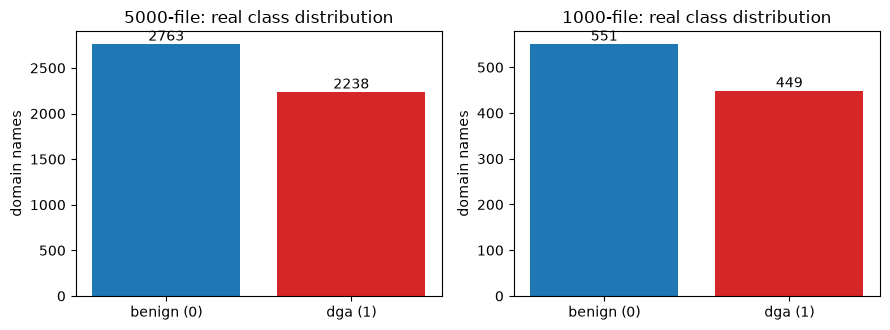

In [7]:
for name, d in [("5000-file (QHTC data)", df5000), ("1000-file (VQC / QSVC / Pegasos / QNN data)", df1000)]:
    vc = d["Result"].value_counts().sort_index()
    print(f"{name}: shape {d.shape}")
    print("  feature names :", FEATURES)
    print("  label column  : 'Result'; original label values and counts:", {int(k): int(v) for k, v in vc.items()}, "(0 = benign, 1 = dga)")
    print(d[FEATURES].describe().loc[["mean", "std", "min", "max"]].round(3).to_string())
    print()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, d) in zip(axes, [("5000-file", df5000), ("1000-file", df1000)]):
    vc = d["Result"].value_counts().sort_index()
    bars = ax.bar(CLASS_NAMES, vc.values, color=["tab:blue", "tab:red"])
    ax.bar_label(bars); ax.set_title(f"{name}: real class distribution"); ax.set_ylabel("domain names")
plt.tight_layout(); plt.show()

5000-file, development rows vs locked held-out: PCA explained variance of the two display components [0.645, 0.202] (training rows: 4901, circled: 100 test rows)


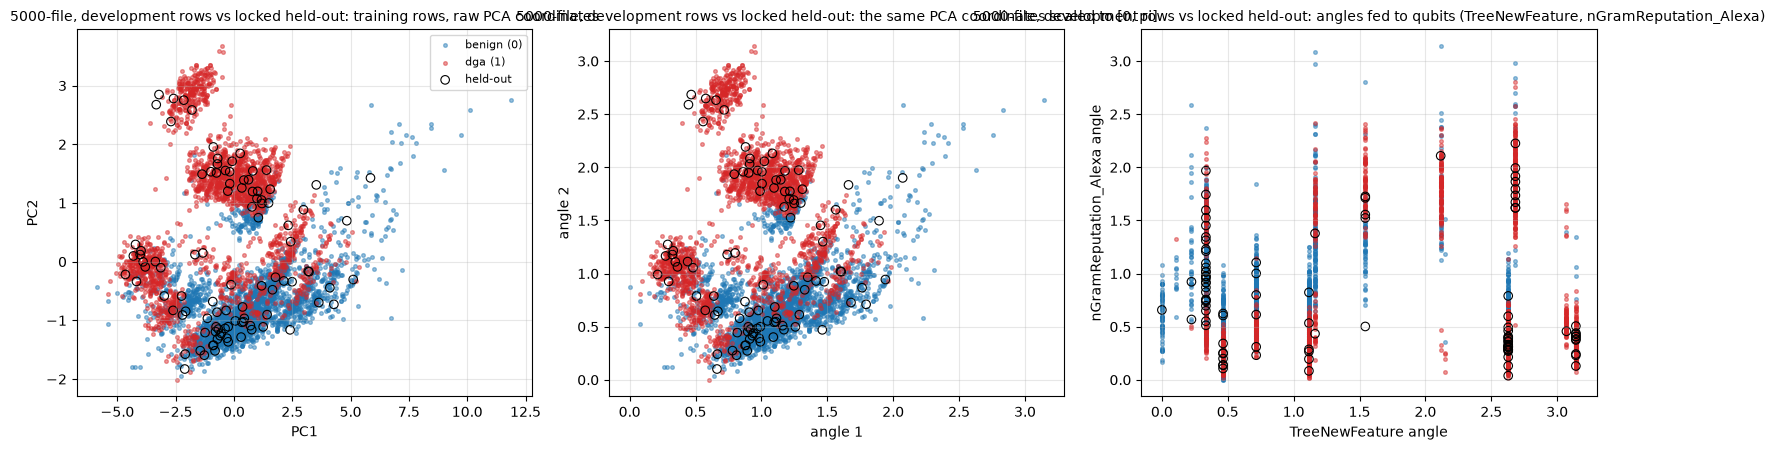

1000-file, authors' split (random_state=7): PCA explained variance of the two display components [0.669, 0.19] (training rows: 700, circled: 300 test rows)


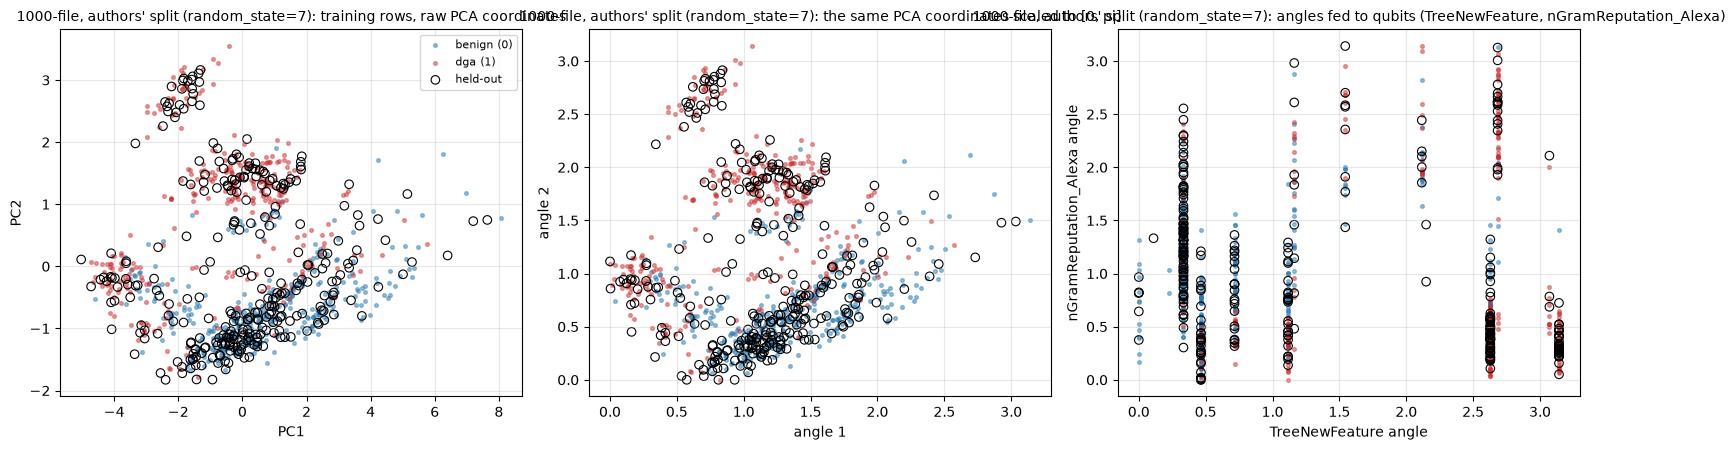

In [8]:
def scatter_panel(ax, Z, y, title, xlabel, ylabel, Zh=None, yh=None):
    for c, col in [(0, "tab:blue"), (1, "tab:red")]:
        ax.scatter(Z[y == c, 0], Z[y == c, 1], s=7, alpha=0.45, color=col, label=CLASS_NAMES[c])
    if Zh is not None:
        for c, col in [(0, "tab:blue"), (1, "tab:red")]:
            ax.scatter(Zh[yh == c, 0], Zh[yh == c, 1], s=38, facecolors="none", edgecolors="black", linewidths=0.8, label="held-out" if c == 0 else None)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=0.3)

def explore(df, train_idx, test_idx, label, strongest=("TreeNewFeature", "nGramReputation_Alexa")):
    X = df[FEATURES].values.astype(float); y = df["Result"].values.astype(int)
    std = StandardScaler().fit(X[train_idx])
    pca = PCA(n_components=2, random_state=SEED).fit(std.transform(X[train_idx]))        # fitted on the training rows only
    Ztr, Zte = pca.transform(std.transform(X[train_idx])), pca.transform(std.transform(X[test_idx]))
    ang = MinMaxScaler((0, np.pi)).fit(Ztr)                                              # angle encoding [0, pi], fitted on the training rows
    Atr, Ate = ang.transform(Ztr), np.clip(ang.transform(Zte), 0, np.pi)
    j = [FEATURES.index(f) for f in strongest]
    fa = MinMaxScaler((0, np.pi)).fit(X[train_idx][:, j])
    Ftr, Fte = fa.transform(X[train_idx][:, j]), np.clip(fa.transform(X[test_idx][:, j]), 0, np.pi)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    scatter_panel(axes[0], Ztr, y[train_idx], f"{label}: training rows, raw PCA coordinates", "PC1", "PC2", Zte, y[test_idx])
    scatter_panel(axes[1], Atr, y[train_idx], f"{label}: the same PCA coordinates scaled to [0, pi]", "angle 1", "angle 2", Ate, y[test_idx])
    scatter_panel(axes[2], Ftr, y[train_idx], f"{label}: angles fed to qubits ({strongest[0]}, {strongest[1]})", strongest[0] + " angle", strongest[1] + " angle", Fte, y[test_idx])
    axes[0].legend(fontsize=8, loc="best")
    print(f"{label}: PCA explained variance of the two display components {pca.explained_variance_ratio_.round(3).tolist()} (training rows: {len(train_idx)}, circled: {len(test_idx)} test rows)")
    plt.tight_layout(); plt.show()

# 5000-file: the correction's split (4901 development rows, 100 locked held-out rows)
explore(df5000.iloc[:lock["N"]], DEV, HELD, "5000-file, development rows vs locked held-out")
# 1000-file: the authors' VQC split (Paper05: train_size=700, test_size=300, random_state=7)
n_h = len(df1000)
_tr, _te = train_test_split(np.arange(n_h), train_size=min(700, int(0.7 * n_h)), test_size=min(300, n_h - min(700, int(0.7 * n_h))), random_state=AZ_SPLIT_SEED)
explore(df1000, _tr, _te, "1000-file, authors' split (random_state=7)")

## Quantum Circuit Architecture

Every gate-based model that this notebook executes is drawn below from the Qiskit object that is actually passed to the
simulator, with its qubit count, depth (after decomposing the library blocks into elementary gates) and the number of
trainable and of data-encoding parameters. The paper omits the circuit details of the QNNs and of the Pegasos/QSVC kernel;
the authors' `azure/` notebooks fix them and are followed (see the table in the paper summary). Architectures:

| Model | Circuit | Source |
|---|---|---|
| quantum walk (original QHTC) | `ZFeatureMap`, one H and one phase gate per qubit, no entanglement, no trainable parameter | paper Algorithm 3, `Paper02` |
| corrected QHTC | `IQP_d1_linear`: H, `Rz(pi x_i)`, then `CX Rz(pi x_i x_j) CX` on the 6 neighbouring pairs; 14 Pauli expectations read out | Author Correction, `streaming_iqp.py` |
| VQC, hand-written VQC | `ZFeatureMap(7, reps=1)` + `RealAmplitudes(7, reps=1, entanglement="pairwise")` + measurement of all qubits | `Paper05` |
| QSVC, PegasosQSVC | `ZFeatureMap(7, reps=1)` inside the compute-uncompute fidelity circuit | `Paper06`, `Paper07` |
| SamplerQNN | `ZZFeatureMap(7)` (2 repetitions, full entanglement) + `RealAmplitudes(7, reps=1)`, parity read-out | `Paper03` |
| EstimatorQNN | `ZZFeatureMap(7)` + `RealAmplitudes(7)` (3 repetitions), observable $Z^{\otimes 7}$ | `Paper04` |

In [9]:
# ---- the circuit builders used by the models below (same objects are passed to VQC / QNNs / kernels) ----
FM_Z   = z_feature_map(N_QUBITS, reps=1)                                            # Paper05/06/07: ZFeatureMap(7, reps=1)
ANS_VQC = real_amplitudes(N_QUBITS, reps=1, entanglement="pairwise")               # Paper05: RealAmplitudes(7, reps=1, entanglement="pairwise")
FM_ZZ  = zz_feature_map(N_QUBITS)                                                   # Paper03/04: ZZFeatureMap(7) (reps=2, full entanglement)
ANS_SAMPLER   = real_amplitudes(N_QUBITS, reps=1)                                  # Paper03: RealAmplitudes(7, reps=1)
ANS_ESTIMATOR = real_amplitudes(N_QUBITS)                                           # Paper04: RealAmplitudes(7), default 3 repetitions

def compose(fm, ans, measure=False):
    qc = QuantumCircuit(N_QUBITS); qc.compose(fm, inplace=True); qc.compose(ans, inplace=True)
    if measure: qc.measure_all()
    return qc

CIRCUITS = {   # name -> (circuit, number of data-encoding parameters)
    "quantum walk map (original QHTC), one row": (FM_Z.assign_parameters(StandardScaler().fit_transform(df5000[FEATURES].values.astype(float))[0]), 0),
    "IQP_d1_linear (corrected QHTC), one row": (si.build_iqp_circuit(lock["X01"][0], 1, "linear"), 0),
    "VQC / hand-written VQC (ZFeatureMap + RealAmplitudes pairwise + measure)": (compose(FM_Z, ANS_VQC, measure=True), FM_Z.num_parameters),
    "SamplerQNN (ZZFeatureMap + RealAmplitudes reps=1)": (compose(FM_ZZ, ANS_SAMPLER), FM_ZZ.num_parameters),
    "EstimatorQNN (ZZFeatureMap + RealAmplitudes reps=3)": (compose(FM_ZZ, ANS_ESTIMATOR), FM_ZZ.num_parameters),
}
rows = []
for name, (qc, n_in) in CIRCUITS.items():
    flat = qc.decompose(reps=3)
    ops = {k: v for k, v in flat.count_ops().items() if k != "barrier"}
    rows.append(dict(circuit=name, qubits=qc.num_qubits, depth_decomposed=flat.depth(), data_encoding_params=n_in,
                     trainable_params=qc.num_parameters - n_in, gates=sum(ops.values()), gate_mix=dict(sorted(ops.items()))))
display(pd.DataFrame(rows).set_index("circuit"))
print("IQP_d1_linear: the 7 + 6 rotation angles are fixed by the data row (pi*x_i and pi*x_i*x_j), nothing is trained; the 14 outputs are read from the final state.")

,qubits,depth_decomposed,data_encoding_params,trainable_params,gates,gate_mix
circuit,,,,,,
"quantum walk map (original QHTC), one row",7,2,0,0,14,{'u': 14}
"IQP_d1_linear (corrected QHTC), one row",7,20,0,0,32,"{'cx': 12, 'u': 20}"
VQC / hand-written VQC (ZFeatureMap + RealAmplitudes pairwise + measure),7,7,7,14,41,"{'cx': 6, 'measure': 7, 'u': 28}"
SamplerQNN (ZZFeatureMap + RealAmplitudes reps=1),7,66,7,14,174,"{'cx': 90, 'u': 84}"
EstimatorQNN (ZZFeatureMap + RealAmplitudes reps=3),7,72,7,28,200,"{'cx': 102, 'u': 98}"


IQP_d1_linear: the 7 + 6 rotation angles are fixed by the data row (pi*x_i and pi*x_i*x_j), nothing is trained; the 14 outputs are read from the final state.


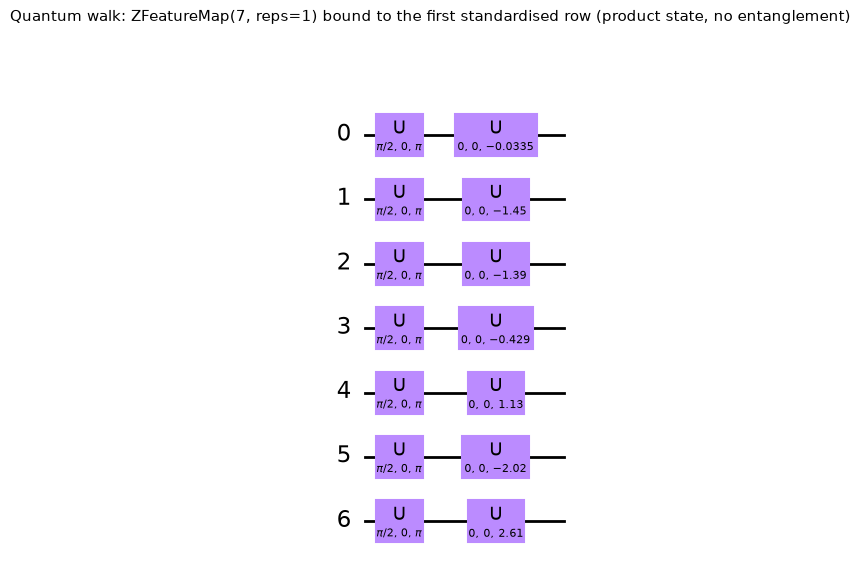

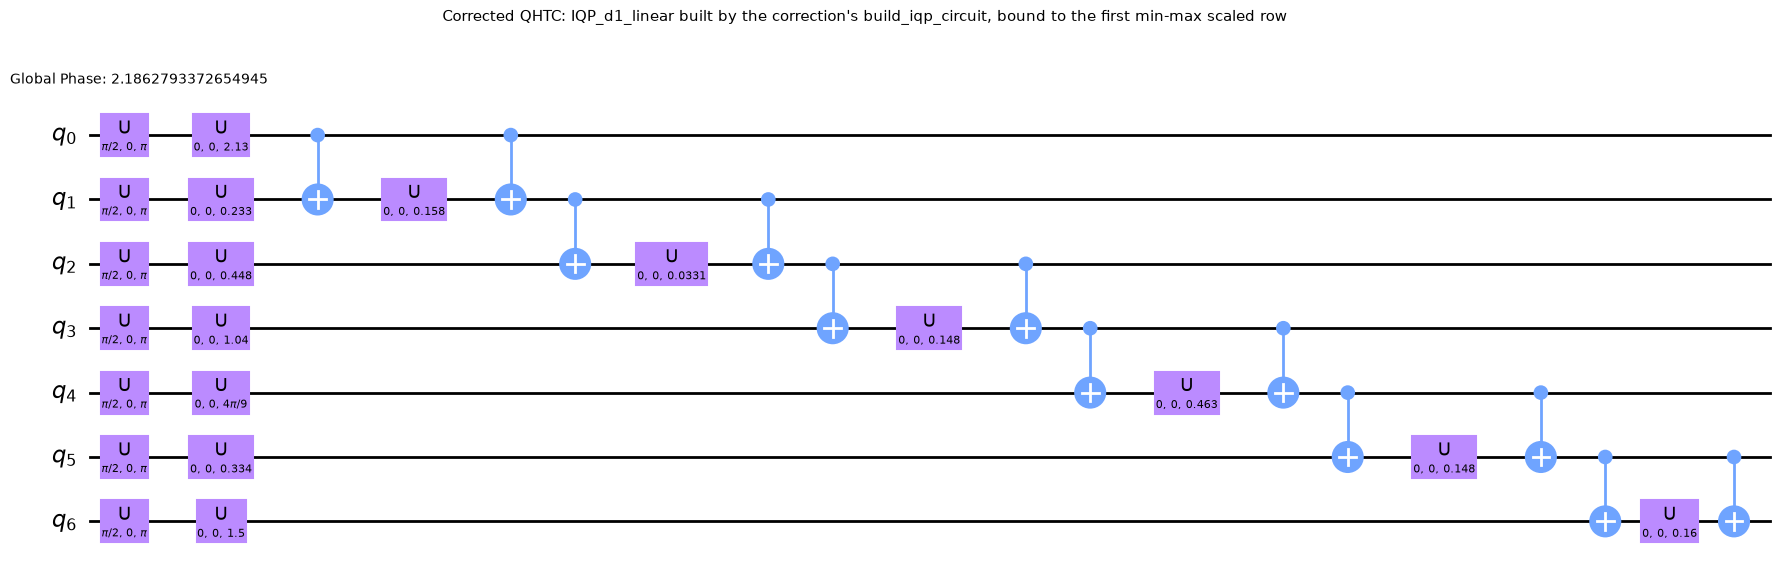

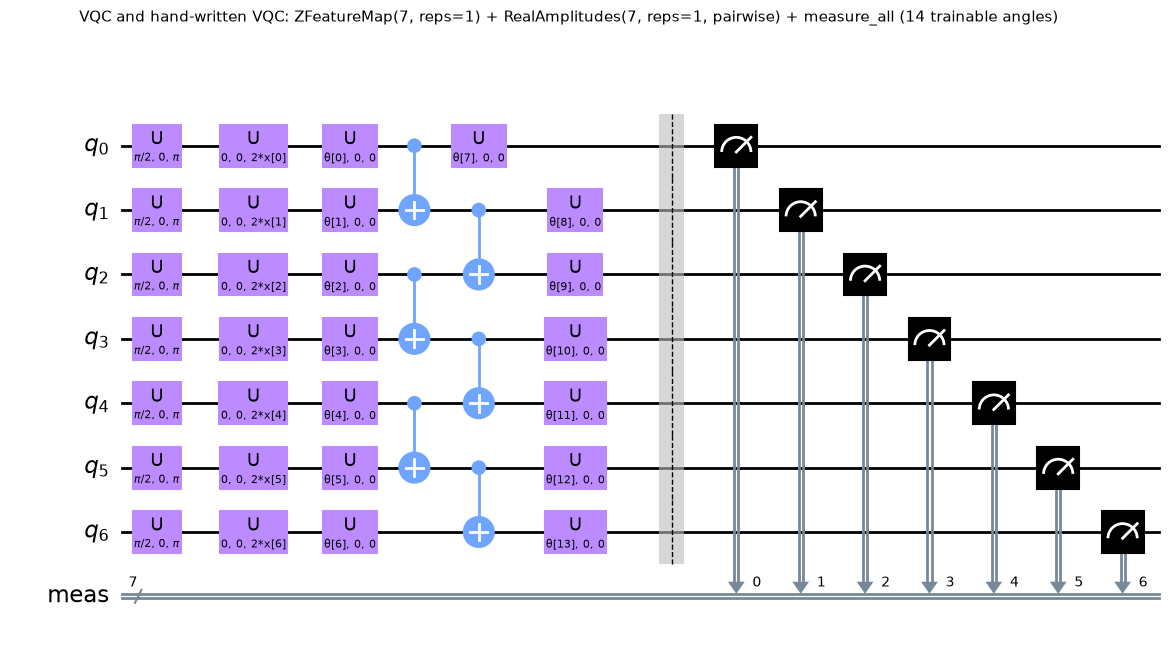

In [10]:
def show(qc, title, fold=36, decompose=True):
    fig = qc.decompose(reps=3).draw("mpl", fold=fold, style="clifford")      # library blocks -> elementary gates (the executed gate list)
    fig.suptitle(title, fontsize=11, y=1.0)
    display(fig); plt.close(fig)

show(CIRCUITS["quantum walk map (original QHTC), one row"][0], "Quantum walk: ZFeatureMap(7, reps=1) bound to the first standardised row (product state, no entanglement)", decompose=False)
show(CIRCUITS["IQP_d1_linear (corrected QHTC), one row"][0], "Corrected QHTC: IQP_d1_linear built by the correction's build_iqp_circuit, bound to the first min-max scaled row", fold=60, decompose=False)
show(CIRCUITS["VQC / hand-written VQC (ZFeatureMap + RealAmplitudes pairwise + measure)"][0], "VQC and hand-written VQC: ZFeatureMap(7, reps=1) + RealAmplitudes(7, reps=1, pairwise) + measure_all (14 trainable angles)", fold=60, decompose=False)

kernel circuit: 7 qubits, depth 4, 0 trainable parameters; |<0|U(xb)^+ U(xa)|0>|^2 = 0.337558 = statevector kernel 0.337558


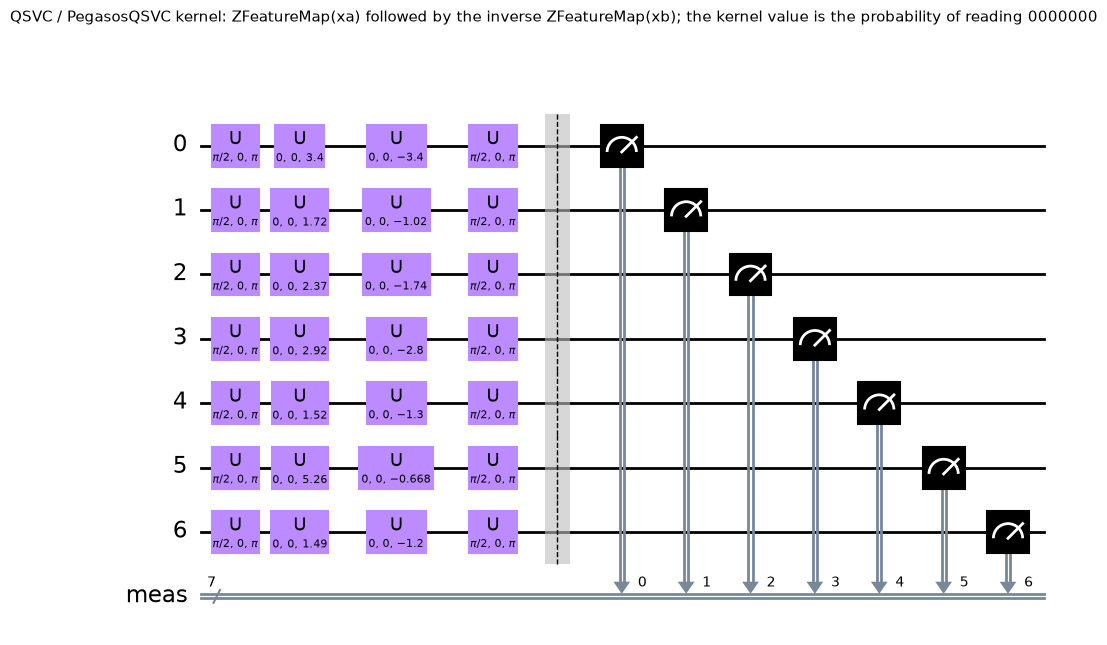

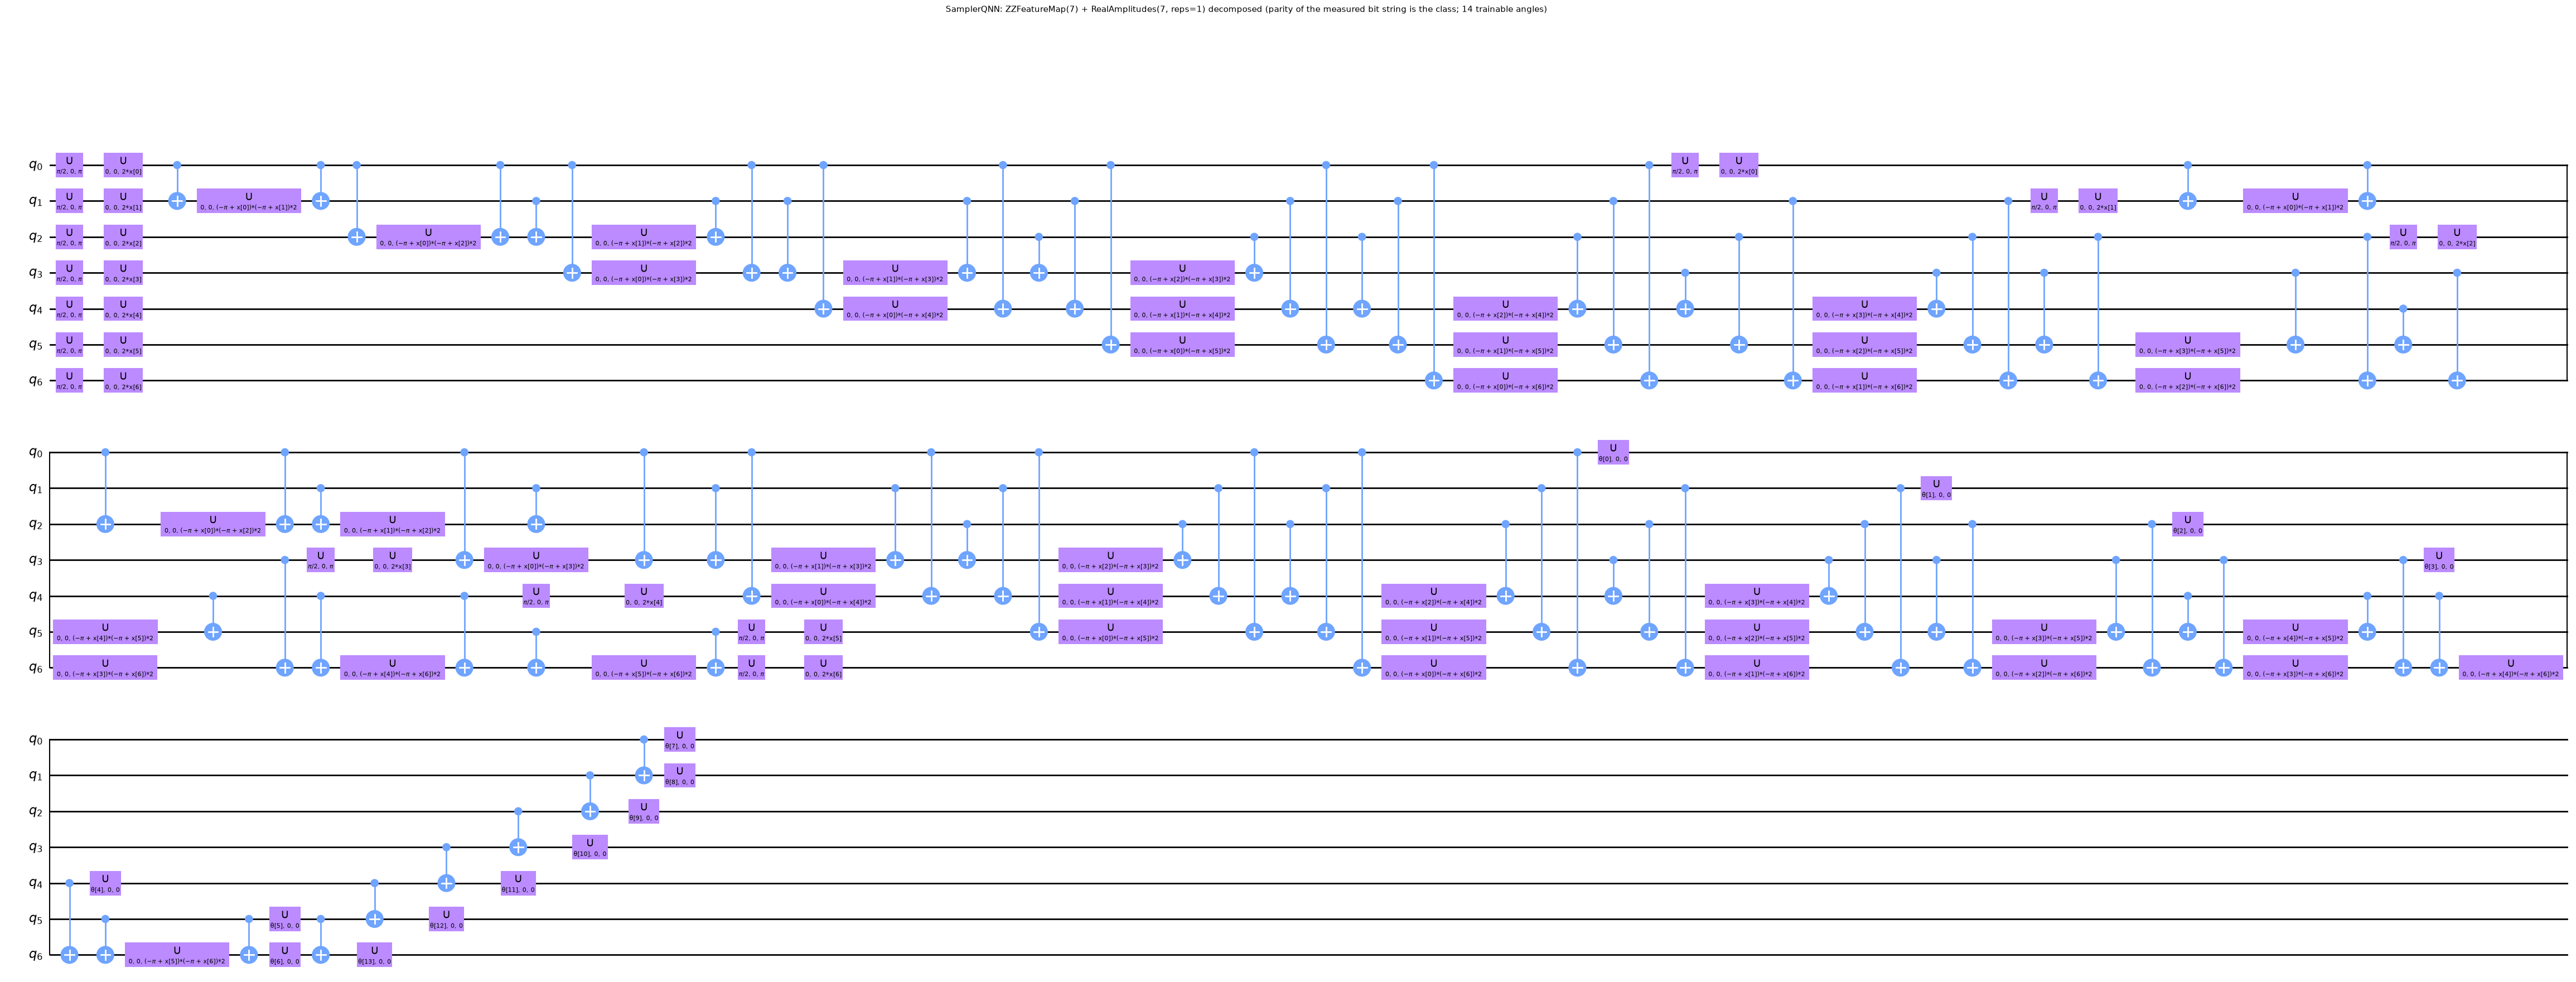

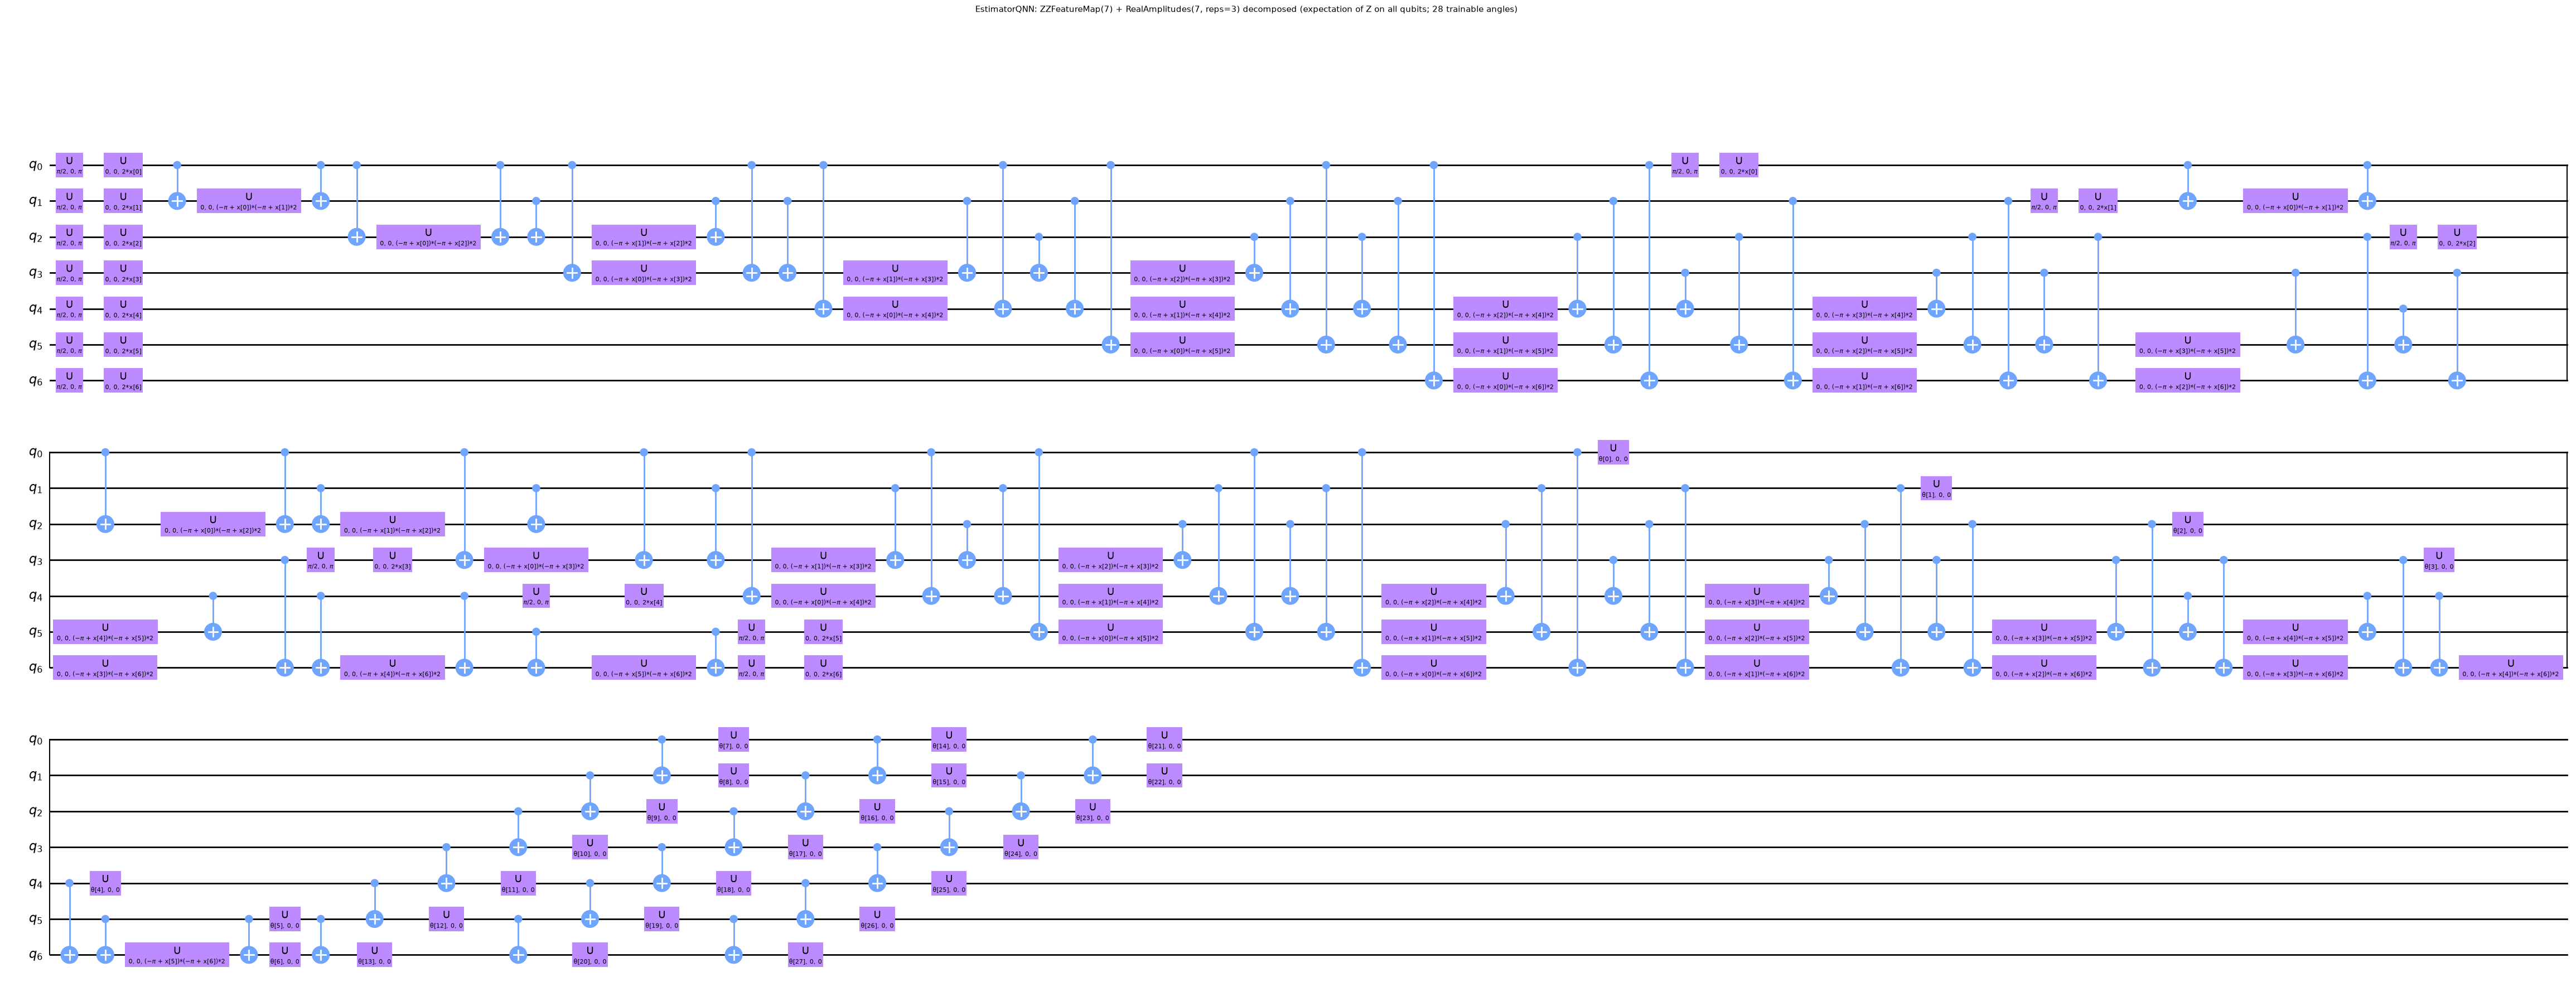

In [11]:
# the kernel circuit of QSVC / PegasosQSVC: compute-uncompute fidelity of two rows, drawn for two real scaled rows;
# the statevector kernel is checked against it (|<0|U(y)^dagger U(x)|0>|^2) so that the drawn circuit is the one whose value is used
xa, xb = MinMaxScaler((0, np.pi)).fit_transform(df1000[FEATURES].values.astype(float))[:2]
fid = FM_Z.assign_parameters(xa).compose(FM_Z.assign_parameters(xb).inverse())
p0 = abs(Statevector(fid)[0]) ** 2
k_check = FidelityStatevectorKernel(feature_map=FM_Z).evaluate(xa[None], xb[None])[0, 0]
assert abs(p0 - k_check) < 1e-9, (p0, k_check)
print(f"kernel circuit: {fid.num_qubits} qubits, depth {fid.decompose().depth()}, 0 trainable parameters; |<0|U(xb)^+ U(xa)|0>|^2 = {p0:.6f} = statevector kernel {k_check:.6f}")
fid_m = fid.copy(); fid_m.measure_all()
show(fid_m, "QSVC / PegasosQSVC kernel: ZFeatureMap(xa) followed by the inverse ZFeatureMap(xb); the kernel value is the probability of reading 0000000", fold=60, decompose=False)
show(CIRCUITS["SamplerQNN (ZZFeatureMap + RealAmplitudes reps=1)"][0], "SamplerQNN: ZZFeatureMap(7) + RealAmplitudes(7, reps=1) decomposed (parity of the measured bit string is the class; 14 trainable angles)", fold=70)
show(CIRCUITS["EstimatorQNN (ZZFeatureMap + RealAmplitudes reps=3)"][0], "EstimatorQNN: ZZFeatureMap(7) + RealAmplitudes(7, reps=3) decomposed (expectation of Z on all qubits; 28 trainable angles)", fold=70)

## 2. Original QHTC step 1: the "quantum walk" feature

The paper maps every feature row $x = (x_0, \dots, x_6)$ (after standardisation) into a 7-qubit `ZFeatureMap` state.
`ZFeatureMap` with one repetition applies a Hadamard and then a phase gate $P(2x_i)$ to qubit $i$, so the state is a
*product* state

$$|\phi(x)\rangle = \bigotimes_{i=0}^{6} \frac{|0\rangle + e^{2 i x_i}|1\rangle}{\sqrt 2}.$$

The code then takes the reduced density matrix $\rho_i$ of each qubit (a partial trace over the other six), computes
the trace distance $D(\rho_i, \rho_{i+1}) = \tfrac12 \|\rho_i - \rho_{i+1}\|_1$ between neighbours around the cycle
$0 \to 1 \to \dots \to 6 \to 0$, and sums the seven distances. The paper calls this sum the *quantum walk* and it is
the single number the Hoeffding tree sees.

Because the state is a product state, every $\rho_i$ is pure and the trace distance between two pure qubit states is
$\sqrt{1 - |\langle\phi_i|\phi_{i+1}\rangle|^2}$ with $|\langle\phi_i|\phi_{i+1}\rangle| = |\cos(x_i - x_{i+1})|$, so

$$\text{walk}(x) = \sum_{i=0}^{6} \big|\sin(x_i - x_{i+1 \bmod 7})\big| .$$

The cell below implements the measurement with Qiskit exactly as the paper's `QHTC_Distance_AER` does (statevector,
`partial_trace`, trace distance), checks it on the paper's own example (`parameters = [1, 2, ..., 7]` gives
`5.3282414070463044` in the published notebook) and against the closed form on `N_WALK_QISKIT` real rows. The closed
form is then used for the remaining rows: it is the same number, computed in nanoseconds instead of milliseconds.

In [12]:
def trace_distance(rho, sigma):
    ev = np.linalg.eigvalsh((rho - sigma).data)          # the difference is Hermitian: 1/2 sum |eigenvalues| = 1/2 trace norm
    return 0.5 * float(np.abs(ev).sum())

def quantum_walk_qiskit(x):
    """The paper's QHTC distance: ZFeatureMap state of the 7 features, reduced density matrix per qubit,
    trace distance between cyclic neighbours, summed."""
    qc = z_feature_map(N_QUBITS, reps=1).assign_parameters(np.asarray(x, dtype=float))   # H + P(2 x_i) on qubit i
    sv = Statevector(qc)
    dms = [DensityMatrix(partial_trace(sv, [j for j in range(N_QUBITS) if j != i])) for i in range(N_QUBITS)]
    return sum(trace_distance(dms[i], dms[(i + 1) % N_QUBITS]) for i in range(N_QUBITS))

def quantum_walk_closed_form(X):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    return np.abs(np.sin(X - np.roll(X, -1, axis=1))).sum(axis=1)

example = np.arange(1, 8, dtype=float)
print(f"paper's example parameters 1..7: Qiskit {quantum_walk_qiskit(example):.16f} | closed form {quantum_walk_closed_form(example)[0]:.16f}"
      f" | published notebook 5.3282414070463044")

# the paper standardises all 5000 rows at once (StandardScaler.fit_transform on the whole file)
df_q  = df5000 if N_QHTC_ROWS is None else df5000.iloc[:N_QHTC_ROWS]
X_q_raw = df_q[FEATURES].values.astype(float)
y_q     = df_q["Result"].values.astype(int)
X_q_std = StandardScaler().fit_transform(X_q_raw)        # paper protocol (leakage-free refit comes in section 4)

n_check = len(X_q_std) if N_WALK_QISKIT is None else min(N_WALK_QISKIT, len(X_q_std))
t0 = time.perf_counter()
walk_qiskit = np.array([quantum_walk_qiskit(x) for x in X_q_std[:n_check]])
t_qiskit = time.perf_counter() - t0
walk_closed = quantum_walk_closed_form(X_q_std)
assert np.allclose(walk_qiskit, walk_closed[:n_check], atol=1e-9), "Qiskit simulation and closed form disagree"
print(f"Qiskit statevector walk for {n_check} rows: {t_qiskit:.1f} s ({1e3*t_qiskit/n_check:.1f} ms/row); max |Qiskit - closed form| = "
      f"{np.abs(walk_qiskit - walk_closed[:n_check]).max():.1e}")
walk_q = walk_closed.copy(); walk_q[:n_check] = walk_qiskit            # Qiskit values where simulated, closed form elsewhere
print(f"quantum walk of {len(walk_q)} rows: min {walk_q.min():.3f}, max {walk_q.max():.3f}, distinct values {len(np.unique(walk_q))}")

paper's example parameters 1..7: Qiskit 5.3282414070462991 | closed form 5.3282414070463053 | published notebook 5.3282414070463044


Qiskit statevector walk for 5001 rows: 26.4 s (5.3 ms/row); max |Qiskit - closed form| = 9.8e-15
quantum walk of 5001 rows: min 1.099, max 6.520, distinct values 4970


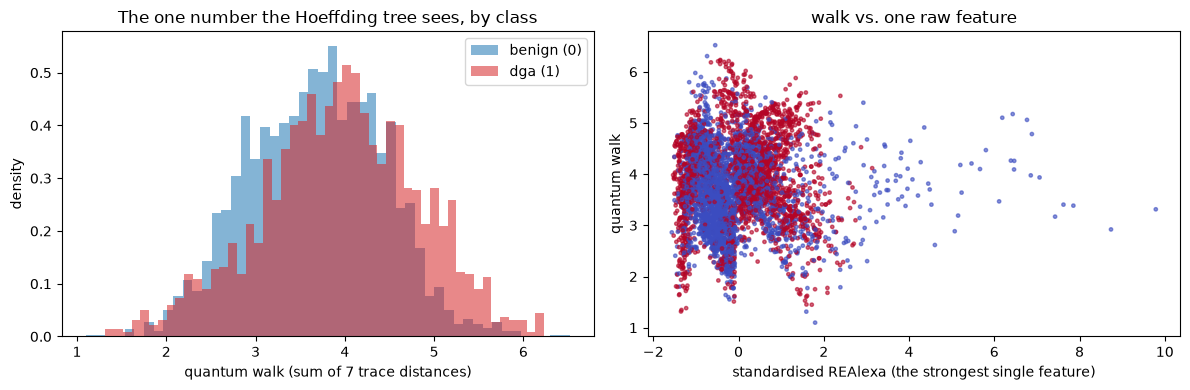

ranking power (AUC) of the walk alone: 0.595 | best single raw feature: TreeNewFeature 0.874


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c, col in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0].hist(walk_q[y_q == c], bins=50, alpha=0.55, color=col, label=CLASS_NAMES[c], density=True)
axes[0].set_xlabel("quantum walk (sum of 7 trace distances)"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("The one number the Hoeffding tree sees, by class")
axes[1].scatter(X_q_std[:, 1], walk_q, c=y_q, cmap="coolwarm", s=6, alpha=0.6)
axes[1].set_xlabel("standardised REAlexa (the strongest single feature)"); axes[1].set_ylabel("quantum walk")
axes[1].set_title("walk vs. one raw feature")
plt.tight_layout(); plt.show()

auc_walk = roc_auc_score(y_q, walk_q); auc_walk = max(auc_walk, 1 - auc_walk)
best_single = max((max(roc_auc_score(y_q, X_q_std[:, j]), 1 - roc_auc_score(y_q, X_q_std[:, j])), f) for j, f in enumerate(FEATURES))
print(f"ranking power (AUC) of the walk alone: {auc_walk:.3f} | best single raw feature: {best_single[1]} {best_single[0]:.3f}")

## 3. Original QHTC step 2: the paper's Hoeffding tree (Algorithms 1-3) and Table 6

The paper prints its Hoeffding tree as Algorithms 1 and 2 and the batch-wise training loop as Algorithm 3; the authors' notebook
`Paper02_QHTC_AER_Simulator.ipynb` contains the same code. The class below is that code (comments shortened, logic untouched);
the next cell **executes the authors' own class from the downloaded, SHA-256-checked `Paper02` notebook next to it and compares
their predictions row by row**. The tree keeps class counts per node, computes a node's error rate, and splits a node when
the error rate exceeds the Hoeffding bound $\sqrt{R^2 \ln(1/\delta) / (2n)}$ with $\delta = 0.01$; children are keyed by
the *string of the attribute value*, i.e. the tree treats the walk value as a categorical attribute.

Algorithm 3 then walks over the 5000 rows in batches of 1000. For batch $k$ the training set is *every row outside the
batch* and the test set is the batch; the tree is updated with `partial_fit` (it is never re-initialised) and scored on
the batch; accuracy, F1 and the AUC of the hard predictions are recorded. That is exactly what the cells below do,
and the per-batch numbers are the paper's Table 6.

In [14]:
class PaperHoeffdingTreeClassifier:
    """Algorithms 1 and 2 of the paper, as published in Paper02_QHTC_AER_Simulator.ipynb (unchanged logic)."""
    def __init__(self, n_features, n_classes, delta=HT_DELTA, tie_threshold=HT_TAU):
        self.n_features, self.n_classes, self.delta, self.tie_threshold = n_features, n_classes, delta, tie_threshold
        self.root = PaperTreeNode(self.delta)

    def predict(self, X):
        y_pred = []
        for x in X:
            node = self.root
            while not node.is_leaf():
                if node.split_attr is None:
                    break
                feature_val = str(x[node.split_attr])
                if feature_val not in node.children:
                    break
                node = node.children[feature_val]
            y_pred.append(node.get_majority_class())
        return y_pred

    def partial_fit(self, X, y):
        for i in range(X.shape[0]):
            self._update_statistics(X[i], y[i])
            self._attempt_split(self.root)

    def _update_statistics(self, x, label):
        node = self.root
        node.total_samples += 1
        node.class_counts[label] = node.class_counts.get(label, 0) + 1
        while node.is_split():
            attr_val = str(x[node.split_attr])
            if attr_val not in node.children:
                node.children[attr_val] = PaperTreeNode(self.delta)
            node = node.children[attr_val]
            node.total_samples += 1
            node.class_counts[label] = node.class_counts.get(label, 0) + 1

    def _attempt_split(self, node):
        if not node.is_split():
            if node.total_samples >= 2:
                node.compute_error_rate()
            if node.total_samples >= 2 and node.error_rate > self._hoeffding_bound(node.total_samples):
                self._split_node(node)
        else:
            for child in node.children.values():
                self._attempt_split(child)

    def _split_node(self, node):
        node.compute_best_splitting_attribute(self.n_classes, self.n_features)
        for attr_val in node.children:
            child = node.children[attr_val]
            if child.total_samples >= 2:
                child.compute_error_rate()
            if child.total_samples < 2 or child.error_rate <= self._hoeffding_bound(child.total_samples):
                continue
            leaf_node = PaperTreeNode(self.delta)
            leaf_node.label = child.get_majority_class()
            node.children[attr_val] = leaf_node

    def _hoeffding_bound(self, n):
        return np.sqrt((self.n_classes * np.log(1 / self.delta)) / (2 * n))


class PaperTreeNode:
    def __init__(self, delta):
        self.split_attr, self.children, self.class_counts = None, {}, {}
        self.total_samples, self.error_rate, self.label, self.delta = 0, 0.0, None, delta

    def is_leaf(self):  return not self.children
    def is_split(self): return self.split_attr is not None

    def compute_error_rate(self):
        self.error_rate = (self.total_samples - max(self.class_counts.values())) / float(self.total_samples)

    def compute_best_splitting_attribute(self, n_classes, n_features):
        best_gain, best_attr = -np.inf, None
        for attr in range(n_features):
            class_counts_per_value, total_samples_per_value = {}, {}
            for attr_val, child in self.children.items():          # NB: empty for a node that has never been split
                class_counts_per_value[attr_val] = child.class_counts.get(attr_val, np.zeros(n_classes))
                total_samples_per_value[attr_val] = child.total_samples
            split_gain = self._compute_hoeffding_bound_gain(class_counts_per_value, total_samples_per_value, n_classes, self.total_samples)
            if split_gain > best_gain:
                best_gain, best_attr = split_gain, attr
        if best_attr is not None:
            self.split_attr = best_attr

    def _compute_hoeffding_bound_gain(self, class_counts_per_value, total_samples_per_value, n_classes, total_samples):
        gain = 0.0
        for attr_val in class_counts_per_value:
            class_counts = class_counts_per_value[attr_val]
            total_samples_val = total_samples_per_value[attr_val]
            error_rate_val = (total_samples_val - np.max(class_counts)) / total_samples_val
            gain -= total_samples_val / total_samples * self._hoeffding_bound(error_rate_val)
        return gain

    def _hoeffding_bound(self, error_rate):
        R = 1
        return np.sqrt((R ** 2 * np.log(1 / self.delta)) / (2 * error_rate))

    def get_majority_class(self):
        max_count, majority_class = -np.inf, None
        for class_label, count in self.class_counts.items():
            if count > max_count:
                max_count, majority_class = count, class_label
        return majority_class

print("paper's Hoeffding tree defined; Hoeffding bound at n = 2, 20, 1000 rows:",
      [round(PaperHoeffdingTreeClassifier(1, 2)._hoeffding_bound(n), 3) for n in (2, 20, 1000)])

paper's Hoeffding tree defined; Hoeffding bound at n = 2, 20, 1000 rows: [np.float64(1.517), np.float64(0.48), np.float64(0.068)]


In [15]:
# --- the authors' own tree class, taken from the pinned Paper02 notebook, against the re-implementation above ---
az02 = json.loads(LOCAL["Paper02_QHTC_AER_Simulator.ipynb"].read_text(encoding="utf-8"))
tree_src = next("".join(c["source"]) for c in az02["cells"] if c["cell_type"] == "code" and "class HoeffdingTreeClassifier" in "".join(c["source"]))
classes = [n for n in ast.parse(tree_src).body if isinstance(n, ast.ClassDef)]
AUTH_NS = {"np": np}
exec(compile(ast.Module(body=classes, type_ignores=[]), "Paper02_QHTC_AER_Simulator.ipynb (pinned)", "exec"), AUTH_NS)
AuthorsTree = AUTH_NS["HoeffdingTreeClassifier"]
print("classes executed from the authors' notebook:", [c.name for c in classes])

n_cmp = 1000 if not FAST_MODE else 300
fit_rows, test_rows = np.arange(n_cmp, 2 * n_cmp), np.arange(n_cmp)
Xw = walk_q[:, None].astype(float); yw = y_q.astype(float)
t_a, t_b = AuthorsTree(n_features=1, n_classes=2), PaperHoeffdingTreeClassifier(n_features=1, n_classes=2)
for t in (t_a, t_b):
    t.partial_fit(Xw[fit_rows], yw[fit_rows])
pa, pb = t_a.predict(Xw[test_rows]), t_b.predict(Xw[test_rows])
assert pa == pb, "the re-implementation and the authors' class disagree"
print(f"authors' class and re-implementation: identical predictions on {n_cmp} unseen rows after {n_cmp} training rows "
      f"(accuracy {100*np.mean(np.array([0.0 if p is None else p for p in pa]) == yw[test_rows]):.1f} %), root children {len(t_a.root.children)} = {len(t_b.root.children)}")

classes executed from the authors' notebook: ['HoeffdingTreeClassifier', 'TreeNode']


authors' class and re-implementation: identical predictions on 1000 unseen rows after 1000 training rows (accuracy 56.3 %), root children 980 = 980


batch 1: 1000 test rows | accuracy 57.1 % | F1 4.5 % | AUC 51.1 % | 6.3 s


batch 2: 1000 test rows | accuracy 99.0 % | F1 98.8 % | AUC 98.9 % | 31.5 s


batch 3: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 93.3 s


batch 4: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 130.1 s


batch 5: 1000 test rows | accuracy 100.0 % | F1 100.0 % | AUC 100.0 % | 105.9 s


batch 6: 1 test rows | accuracy 100.0 % | F1 nan % | AUC nan % | 127.2 s

average over the 5 full batches: accuracy 91.2 % | F1 80.7 % | AUC 90.0 %   (paper's Table 6: 91.2 % | 80.7 % | 90.0 % over five batches)
total QHTC time here: walk 26 s (Qiskit, 5001 rows) + tree 494 s   (paper: 1687 s on the Rigetti emulator)


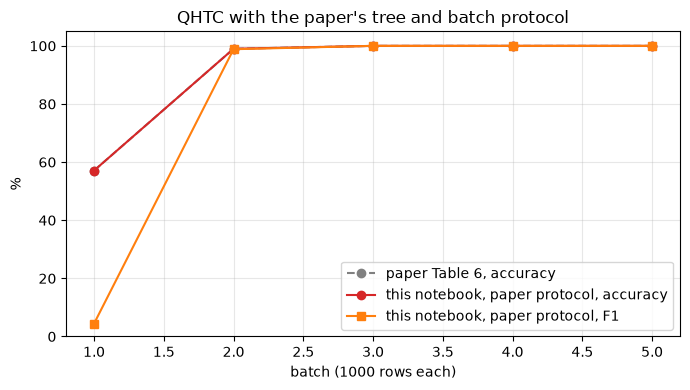

In [16]:
def hard_metrics(y_true, y_pred):
    """accuracy, F1 (DGA positive) and AUC of the hard 0/1 predictions, exactly the three columns of the paper's Table 6."""
    y_pred = np.asarray(y_pred, dtype=float).astype(int); y_true = np.asarray(y_true).astype(int)
    return dict(accuracy=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, zero_division=0),
                auc=roc_auc_score(y_true, y_pred) if len(np.unique(y_true)) > 1 else np.nan)

def run_paper_protocol(walk, labels, batch_size=BATCH_SIZE, verbose=True):
    """Algorithm 3 as published: one tree, never reset; batch k is the test set, every other row is the training set."""
    new_data = np.column_stack([walk, labels.astype(float)])
    htc = PaperHoeffdingTreeClassifier(n_features=1, n_classes=2)
    rows, preds = [], {}
    for i in range(0, len(new_data), batch_size):
        X_train = np.concatenate([new_data[:i, :-1], new_data[i + batch_size:, :-1]])
        y_train = np.concatenate([new_data[:i, -1], new_data[i + batch_size:, -1]])
        X_test, y_test = new_data[i:i + batch_size, :-1], new_data[i:i + batch_size, -1]
        t0 = time.perf_counter()
        htc.partial_fit(X_train, y_train)
        pred = np.array([p if p is not None else 0.0 for p in htc.predict(X_test)], dtype=float)
        k = i // batch_size + 1
        preds[k] = pred
        m = hard_metrics(y_test, pred) if len(X_test) > 1 else dict(accuracy=float(pred[0] == y_test[0]), f1=np.nan, auc=np.nan)
        rows.append(dict(batch=k, n_test=len(X_test), **m, seconds=time.perf_counter() - t0))
        if verbose:
            print(f"batch {k}: {len(X_test)} test rows | accuracy {100*m['accuracy']:.1f} % | F1 {100*m['f1']:.1f} % | AUC {100*m['auc']:.1f} % | {rows[-1]['seconds']:.1f} s")
    return pd.DataFrame(rows), htc, preds

t0 = time.perf_counter()
table6_ours, paper_tree, paper_preds = run_paper_protocol(walk_q, y_q)
t_qhtc_paper = time.perf_counter() - t0
full_batches = table6_ours[table6_ours.n_test == BATCH_SIZE]
avg = full_batches[["accuracy", "f1", "auc"]].mean()
print(f"\naverage over the {len(full_batches)} full batches: accuracy {100*avg.accuracy:.1f} % | F1 {100*avg.f1:.1f} % | AUC {100*avg.auc:.1f} %"
      f"   (paper's Table 6: 91.2 % | 80.7 % | 90.0 % over five batches)")
print(f"total QHTC time here: walk {t_qiskit:.0f} s (Qiskit, {n_check} rows) + tree {t_qhtc_paper:.0f} s   (paper: 1687 s on the Rigetti emulator)")

PAPER_TABLE6 = pd.DataFrame({"batch": [1, 2, 3, 4, 5], "accuracy": [57.1, 99.0, 100.0, 100.0, 100.0],
                             "f1": [4.5, 98.8, 100.0, 100.0, 100.0], "auc": [51.1, 98.9, 100.0, 100.0, 100.0]}).set_index("batch")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(PAPER_TABLE6.index, PAPER_TABLE6.accuracy, "o--", color="gray", label="paper Table 6, accuracy")
ax.plot(full_batches.batch, 100 * full_batches.accuracy, "o-", color="tab:red", label="this notebook, paper protocol, accuracy")
ax.plot(full_batches.batch, 100 * full_batches.f1, "s-", color="tab:orange", label="this notebook, paper protocol, F1")
ax.set_xlabel("batch (1000 rows each)"); ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.grid(alpha=0.3); ax.legend()
ax.set_title("QHTC with the paper's tree and batch protocol"); plt.tight_layout(); plt.show()

### Why batches 2-5 are perfect: looking inside the tree

Two properties of the published code explain the jump from 57 % to 100 %:

1. **The test rows of batch $k \ge 2$ were already training rows.** Batch 2 is tested after the tree has been fitted on
   "everything except batch 1" (which contains batch 2) *and* on "everything except batch 2". The tree is never reset,
   so by the time a batch is scored, every one of its rows has been fed to `partial_fit` at least once. Only batch 1 is
   scored before it has been seen.
2. **The tree memorises rows.** `compute_best_splitting_attribute` loops over the node's children, which are empty when a
   node is first split, so the gain is 0 for every attribute and the split always lands on attribute 0 (the only one
   here). Children are keyed by `str(value)` of the walk, a float with 16 significant digits, so almost every row gets its
   own child whose majority class is its own label. At prediction time, a value never seen falls back to the root's
   majority class (benign), a value seen before returns the label stored with it.

The cell verifies both: the root has thousands of children (one per distinct walk value), almost every row of batch 1
receives the majority class (accuracy = the benign share of the batch, F1 close to 0; the handful of DGA predictions
come from walk values that happen to coincide with a stored row), and 100 % of the rows in later batches were in an
earlier training set. The 99.0 % of batch 2 rather than 100 % comes from the few duplicated walk values whose child node
holds rows of both classes.

In [17]:
root = paper_tree.root
print(f"root: split on attribute {root.split_attr}, {len(root.children)} children for {len(np.unique(walk_q))} distinct walk values, "
      f"{root.total_samples} rows seen in total (each row is fed to partial_fit several times)")
seen = np.zeros(len(walk_q), dtype=bool)
for k in sorted(paper_preds):
    i = (k - 1) * BATCH_SIZE
    test_idx = np.arange(i, min(i + BATCH_SIZE, len(walk_q)))
    frac_seen = seen[test_idx].mean()
    train_idx = np.setdiff1d(np.arange(len(walk_q)), test_idx)   # the rows partial_fit received in this round
    seen[train_idx] = True
    pred = paper_preds[k]
    print(f"batch {k}: {100*frac_seen:5.1f} % of its rows were already training rows | predicted classes {np.unique(pred).astype(int).tolist()} "
          f"| benign share of the batch {100*(1 - y_q[test_idx].mean()):.1f} % | accuracy {100*np.mean(pred == y_q[test_idx]):.1f} %")
print("\nA tree that stores one leaf per distinct float is a lookup table, and the batch protocol asks it to look up rows it has stored.")

root: split on attribute 0, 4970 children for 4970 distinct walk values, 25005 rows seen in total (each row is fed to partial_fit several times)
batch 1:   0.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 56.1 % | accuracy 57.1 %
batch 2: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 56.1 % | accuracy 99.0 %
batch 3: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 54.8 % | accuracy 100.0 %
batch 4: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 53.8 % | accuracy 100.0 %
batch 5: 100.0 % of its rows were already training rows | predicted classes [0, 1] | benign share of the batch 55.5 % | accuracy 100.0 %
batch 6: 100.0 % of its rows were already training rows | predicted classes [1] | benign share of the batch 0.0 % | accuracy 100.0 %

A tree that stores one leaf per distin

### 3.1 The original walk without leakage: `river`'s Hoeffding tree, fold-wise and prequential

What should Algorithm 3 have measured? Two honest protocols are run below with a textbook Hoeffding tree
(`river.tree.HoeffdingTreeClassifier`, Domingos and Hulten's VFDT with the paper's $\delta = 0.01$ and $\tau = 0.05$):

* **Fold-wise** (what Algorithm 3 intends): for each batch $k$ a *fresh* tree is trained incrementally on every other
  batch and scored on batch $k$. The standard scaler that feeds the walk is fitted on the training batches only.
* **Prequential** (how a streaming classifier is actually evaluated): a single tree sees the batches in order; each batch
  is first predicted, then learned ("test-then-train"). The first batch has no prediction yet, so the curve starts at
  batch 2.

Both are run on the quantum walk (QHTC) and on the seven standardised features themselves (the classical Hoeffding tree,
HTC, which the paper mentions but does not report). Four classical batch learners trained on identical inputs
(random forest, RBF-SVM, logistic regression, a CART decision tree) are added fold-wise, so the question "does the walk
help, and does the tree help?" has an answer.

fold-wise runs done in 68 s


Leakage-free results, mean and std over the batches (in %):


accuracy mean  accuracy std  f1 mean  f1 std  auc mean  auc std
protocol               model                 inputs                                                                                  
fold-wise, fresh model DecisionTree          7 standardised features           91.9           0.5     90.9     0.8      91.8      0.6
                                             quantum walk (1 number)           54.8           1.2     50.1     1.8      54.4      1.3
                       LogisticRegression    7 standardised features           91.5           0.6     90.3     0.8      91.2      0.7
                                             quantum walk (1 number)           58.7           0.8     41.8     1.3      56.3      0.7
                       RandomForest          7 standardised features           94.4           0.4     93.8     0.5      94.4      0.4
                                             quantum walk (1 number)           54.8           1.2     50.1     1.8      54.4      1.3
                       SVC (rbf)             7 standardised features           94.3           0.6     93.6     0.6      94.2      0.6
                                             quantum walk (1 number)           60.0           1.0     32.4     1.3      56.3      0.9
fold-wise, fresh tree  HoeffdingTree (river) 7 standardised features           86.3           0.6     85.6     0.9      86.8      0.8
                                             quantum walk (1 number)           56.1           2.2     44.6     2.3      54.6      2.0
prequential, one tree  HoeffdingTree (river) 7 standardised features           85.4           1.7     84.1     2.6      85.4      2.0
                                             quantum walk (1 number)           58.4           1.6     45.8     6.0      56.8      1.8

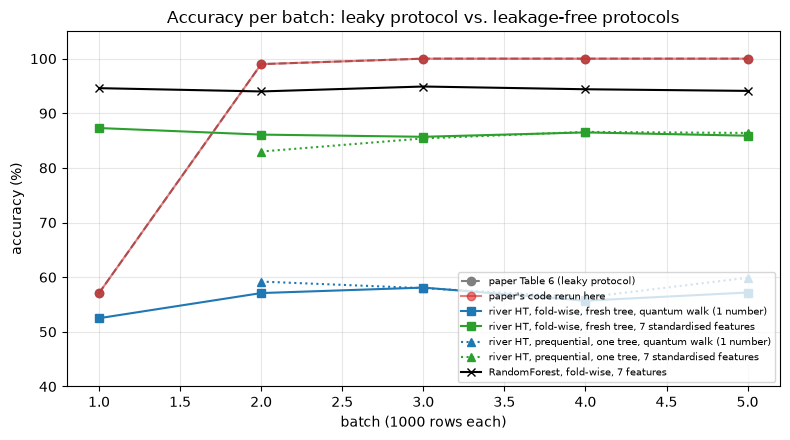

In [18]:
def make_river_ht():
    return river_tree.HoeffdingTreeClassifier(grace_period=HT_GRACE_PERIOD, delta=HT_DELTA, tau=HT_TAU)

def ht_learn(ht, X, y, names, seed):
    order = np.random.default_rng(seed).permutation(len(X))      # CHOICE: the stream order inside a batch is random
    for i in order:
        ht.learn_one(dict(zip(names, map(float, np.atleast_1d(X[i])))), int(y[i]))
    return ht

def ht_predict(ht, X, names):
    out = []
    for x in X:
        p = ht.predict_one(dict(zip(names, map(float, np.atleast_1d(x)))))
        out.append(0 if p is None else int(p))
    return np.array(out)

def classical_models():
    return {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),
            "SVC (rbf)": SVC(kernel="rbf", C=1.0, random_state=SEED),
            "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
            "DecisionTree": DecisionTreeClassifier(random_state=SEED)}

n_batches = len(walk_q) // BATCH_SIZE
batches = [np.arange(k * BATCH_SIZE, (k + 1) * BATCH_SIZE) for k in range(n_batches)]
WALK_NAME, FEAT_NAMES = ["walk"], FEATURES

fold_rows = []
t0 = time.perf_counter()
for k, test_idx in enumerate(batches, start=1):
    train_idx = np.setdiff1d(np.arange(n_batches * BATCH_SIZE), test_idx)
    scaler = StandardScaler().fit(X_q_raw[train_idx])                       # fitted on the training batches only
    Xtr7, Xte7 = scaler.transform(X_q_raw[train_idx]), scaler.transform(X_q_raw[test_idx])
    wtr, wte = quantum_walk_closed_form(Xtr7)[:, None], quantum_walk_closed_form(Xte7)[:, None]
    ytr, yte = y_q[train_idx], y_q[test_idx]
    for inputs, (Xtr, Xte, names) in {"quantum walk (1 number)": (wtr, wte, WALK_NAME), "7 standardised features": (Xtr7, Xte7, FEAT_NAMES)}.items():
        pred = ht_predict(ht_learn(make_river_ht(), Xtr, ytr, names, SEED + k), Xte, names)
        fold_rows.append(dict(protocol="fold-wise, fresh tree", model="HoeffdingTree (river)", inputs=inputs, batch=k, **hard_metrics(yte, pred)))
        for mname, model in classical_models().items():
            pred = model.fit(Xtr, ytr).predict(Xte)
            fold_rows.append(dict(protocol="fold-wise, fresh model", model=mname, inputs=inputs, batch=k, **hard_metrics(yte, pred)))
print(f"fold-wise runs done in {time.perf_counter()-t0:.0f} s")

# prequential: one tree, test-then-train over the batches in order; the scaler is fitted on batch 1 (the first data seen)
preq_rows = []
scaler = StandardScaler().fit(X_q_raw[batches[0]])
X_all7 = scaler.transform(X_q_raw[:n_batches * BATCH_SIZE]); w_all = quantum_walk_closed_form(X_all7)[:, None]
for inputs, (Xs, names) in {"quantum walk (1 number)": (w_all, WALK_NAME), "7 standardised features": (X_all7, FEAT_NAMES)}.items():
    ht = make_river_ht()
    for k, idx in enumerate(batches, start=1):
        if k > 1:
            pred = ht_predict(ht, Xs[idx], names)
            preq_rows.append(dict(protocol="prequential, one tree", model="HoeffdingTree (river)", inputs=inputs, batch=k, **hard_metrics(y_q[idx], pred)))
        ht_learn(ht, Xs[idx], y_q[idx], names, SEED + k)

leakfree = pd.DataFrame(fold_rows + preq_rows)
summary = (leakfree.groupby(["protocol", "model", "inputs"])[["accuracy", "f1", "auc"]].agg(["mean", "std"]) * 100).round(1)
summary.columns = [f"{a} {b}" for a, b in summary.columns]
print("Leakage-free results, mean and std over the batches (in %):")
display(summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(PAPER_TABLE6.index, PAPER_TABLE6.accuracy, "o--", color="gray", label="paper Table 6 (leaky protocol)")
ax.plot(full_batches.batch, 100 * full_batches.accuracy, "o-", color="tab:red", alpha=0.6, label="paper's code rerun here")
for (proto, inputs), style in {("fold-wise, fresh tree", "quantum walk (1 number)"): ("s-", "tab:blue"),
                                ("fold-wise, fresh tree", "7 standardised features"): ("s-", "tab:green"),
                                ("prequential, one tree", "quantum walk (1 number)"): ("^:", "tab:blue"),
                                ("prequential, one tree", "7 standardised features"): ("^:", "tab:green")}.items():
    d = leakfree[(leakfree.protocol == proto) & (leakfree.inputs == inputs) & (leakfree.model == "HoeffdingTree (river)")]
    ax.plot(d.batch, 100 * d.accuracy, style[0], color=style[1], label=f"river HT, {proto}, {inputs}")
d = leakfree[(leakfree.model == "RandomForest") & (leakfree.inputs == "7 standardised features")]
ax.plot(d.batch, 100 * d.accuracy, "x-", color="black", label="RandomForest, fold-wise, 7 features")
ax.set_xlabel("batch (1000 rows each)"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(40, 105); ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right"); ax.set_title("Accuracy per batch: leaky protocol vs. leakage-free protocols")
plt.tight_layout(); plt.show()

## 4. The corrected QHTC of the 2026 Author Correction

What the correction changes, taken from its own text and code (it contains no corrected version of the paper's tree class; it
*replaces* the tree and the encoding):

| | Paper (Algorithms 1-3) | Author Correction (`quantumHTC-repo`) |
|---|---|---|
| encoding | `ZFeatureMap` product state, scalar "quantum walk" (7 trace distances summed), `nFeatures = 1` | `IQP_d1_linear` and 11 other pre-registered circuits; 14 Pauli expectations (7 Z + 7 X), `nFeatures = 14` |
| scaling | `StandardScaler` | `MinMaxScaler` to [0, 1] (all rows, unsupervised) |
| tree | the authors' own class (categorical children keyed by `str(value)`) | `river.tree.HoeffdingTreeClassifier(grace_period=50, delta=1e-7, tau=0.05)`, a new tree for every seed |
| training | `partial_fit` on every row outside batch k, tree never reset | prequential stream over the 4901 development rows (`predict_one` then `learn_one`), in a seeded random order |
| scoring | the rows of batch k, which earlier rounds trained on | 100 locked held-out rows (50 benign, 50 DGA, seed 42) that the tree never sees |
| controls | none | random-label litmus (seed 1234), three seeds, one-sample t-test against the baseline, Benjamini-Hochberg across 12 architectures |
| baseline | none (classical HTC mentioned only) | the same river tree on the 7 raw features: 0.840 |

The cell below runs the correction's `compute_streaming_baseline` and `run_streaming_iqp_one_arch` **as extracted from the
pinned file**, for the architectures in `CORR_ARCHS`, on the correction's data and locked held-out set. The encoder is the
correction's `compute_iqp_features` (7 qubits, Aer statevector), run in `ENCODE_WORKERS` processes.

In [19]:
t0 = time.perf_counter()
c0_stream = RUN_NS["compute_streaming_baseline"](lock)
print(f"C0 (river Hoeffding tree on the raw 7 features): held-out {c0_stream['real_held_mean']:.4f} +/- {c0_stream['real_held_std']:.4f}, "
      f"litmus {c0_stream['litmus_held_mean']:.4f}, seeds {c0_stream['seeds_real']}   (published: 0.840 +/- 0.000, litmus 0.510)")

iqp_archs = {a["name"]: a for a in si.iqp_architectures()}
corr_results = []
for name in CORR_ARCHS:
    t1 = time.perf_counter()
    r = RUN_NS["run_streaming_iqp_one_arch"](iqp_archs[name], lock, n_workers=ENCODE_WORKERS)
    r["family"] = "IQP"
    corr_results.append(r)
    print(f"{name:18s} held-out {r['real_held_mean']:.4f} +/- {r['real_held_std']:.4f} | litmus {r['litmus_held_mean']:.3f} (delta {r['litmus_delta']:+.3f}) "
          f"| p={r['p_value']:.4f} | encode {r['encode_per_sample_ms']:.1f} ms/sample wall ({r['encode_time_s']:.0f} s) | {time.perf_counter()-t1:.0f} s")
t_corr = time.perf_counter() - t0
print(f"corrected QHTC runs finished in {t_corr:.0f} s")

C0 (river Hoeffding tree on the raw 7 features): held-out 0.8400 +/- 0.0000, litmus 0.4700, seeds [0.84, 0.84, 0.84]   (published: 0.840 +/- 0.000, litmus 0.510)


IQP_d1_linear      held-out 0.8700 +/- 0.0000 | litmus 0.513 (delta +0.357) | p=0.0000 | encode 182.5 ms/sample wall (913 s) | 933 s


IQP_d1_alltoall    held-out 0.8900 +/- 0.0082 | litmus 0.453 (delta +0.437) | p=0.0065 | encode 210.5 ms/sample wall (1053 s) | 1068 s
corrected QHTC runs finished in 2007 s


In [20]:
# --- statistics exactly as the correction's main(): BH-FDR over the architectures, then the three filters (F1 uses the published 0.84) ---
pub = pd.read_csv(LOCAL["streaming_results.csv"])
bh = RUN_NS["bh_fdr_correct"]
p_here = np.array([r["p_value"] for r in corr_results])
p_bh_here = bh(p_here)                                                    # BH over the architectures run here
p_pub_all = pub.set_index("name")["p_value"]
p_joint = p_pub_all.copy()
for r in corr_results:
    p_joint[r["name"]] = r["p_value"]                                       # 12 tests: ours where rerun, the published p-value for the rest
p_bh_12 = pd.Series(bh(p_joint.values), index=p_joint.index)
rows = []
for r, pbh in zip(corr_results, p_bh_here):
    r["p_value_bh"] = float(pbh)
    r["verdict"] = RUN_NS["verdict_from_filters"](r["real_held_mean"], r["real_held_std"], r["litmus_delta"], r["delta_vs_c0"], pbh, c0_stream["real_held_std"])
    pr = pub.set_index("name").loc[r["name"]]
    rows.append({"architecture": r["name"], "held-out (here)": round(r["real_held_mean"], 3), "held-out (published)": round(pr.real_held_mean, 3),
                 "std (here)": round(r["real_held_std"], 3), "std (published)": round(pr.real_held_std, 3),
                 "litmus (here)": round(r["litmus_held_mean"], 3), "litmus (published)": round(pr.litmus_held_mean, 3),
                 "p_BH (here, runs only)": round(r["p_value_bh"], 3), "p_BH (12 tests, published rest)": round(float(p_bh_12[r["name"]]), 3),
                 "p_BH (published)": round(pr.p_value_bh, 3), "verdict (here)": r["verdict"], "verdict (published)": pr.verdict})
corr_table = pd.DataFrame(rows).set_index("architecture")
display(corr_table.T if len(corr_table) > 3 else corr_table)
print("not rerun here (published rows of the correction's replacement Table 6, Q-kernel-projection family):")
display(pub[pub.family == "QKproj"][["name", "real_held_mean", "real_held_std", "litmus_held_mean", "p_value_bh", "verdict"]].round(3).set_index("name"))

,held-out (here),held-out (published),std (here),std (published),litmus (here),litmus (published),"p_BH (here, runs only)","p_BH (12 tests, published rest)",p_BH (published),verdict (here),verdict (published)
architecture,,,,,,,,,,,
IQP_d1_linear,0.87,0.897,0.000,0.012,0.513,0.460,0.000,0.000,0.035,CONFIRMED_WIN,CONFIRMED_WIN
IQP_d1_alltoall,0.89,0.887,0.008,0.009,0.453,0.467,0.007,0.026,0.035,CONFIRMED_WIN,CONFIRMED_WIN


not rerun here (published rows of the correction's replacement Table 6, Q-kernel-projection family):


,real_held_mean,real_held_std,litmus_held_mean,p_value_bh,verdict
name,,,,,
QKproj_ZZ_r1,0.823,0.012,0.533,0.993,LOSE
QKproj_ZZ_r2,0.790,0.008,0.583,0.993,LOSE
QKproj_ZZ_r3,0.783,0.021,0.550,0.993,LOSE
QKproj_Pauli_r1,0.853,0.039,0.537,0.505,BORDERLINE


### 4.1 The features, and a per-row look at the 100 held-out rows

`CachedPool` kept every encoded row, so the 14-dimensional IQP features are available without re-simulating. The cell recomputes
the held-out predictions of the correction's streaming loop row by row (same seeds, same stream order, same river parameters) and
**asserts that the accuracies equal the ones the correction's own function just returned**. With per-row predictions the
uncertainty that a three-seed mean hides can be shown: the three seeds change only the order of the 4901 development rows, never
the 100 held-out rows, so the standard deviation across seeds does not measure the sampling error of the held-out set.

In [21]:
HP = RUN_NS["HOEFFDING_PARAMS"]
def feats_iqp(name):
    a = iqp_archs[name]
    return np.array([CachedPool.cache[(X01[i].tobytes(), a["depth"], a["topology"])] for i in range(lock["N"])], dtype=float)

def stream_heldout(F, labels, names, seed):
    """The correction's streaming loop (prequential over the development rows in a seeded random order), returning the held-out predictions."""
    order = DEV.copy(); np.random.default_rng(seed).shuffle(order)
    t = river_tree.HoeffdingTreeClassifier(**HP)
    for i in order:
        d = dict(zip(names, map(float, F[i]))); t.predict_one(d); t.learn_one(d, int(labels[i]))
    out = [t.predict_one(dict(zip(names, map(float, F[i])))) for i in HELD]
    return np.array([-1 if p is None else int(p) for p in out])

N7, N14 = [f"f{j}" for j in range(7)], [f"q{j}" for j in range(14)]
y_held = Y_ALL[HELD]
per_row = {}
for seed in range(RUN_NS["N_SEEDS"]):
    per_row[("C0", seed)] = stream_heldout(X01, Y_ALL, N7, seed)
assert np.allclose([np.mean(per_row[("C0", s)] == y_held) for s in range(3)], c0_stream["seeds_real"]), "C0 held-out accuracies differ from the correction's function"
F_iqp = {}
for r in corr_results:
    F_iqp[r["name"]] = feats_iqp(r["name"])
    for seed in range(3):
        per_row[(r["name"], seed)] = stream_heldout(F_iqp[r["name"]], Y_ALL, N14, seed)
    got = [float(np.mean(per_row[(r["name"], s)] == y_held)) for s in range(3)]
    assert np.allclose(got, r["seeds_real"]), (r["name"], got, r["seeds_real"])
print("per-row held-out predictions reproduce the accuracies returned by the correction's own functions (assertion passed)")

main = CORR_ARCHS[0]
rows = []
for seed in range(3):
    a, b = per_row[(main, seed)] == y_held, per_row[("C0", seed)] == y_held
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p_mc = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    lo, hi = binomtest(int(a.sum()), len(a)).proportion_ci(confidence_level=0.95, method="wilson")
    rows.append({"seed": seed, f"{main} correct": int(a.sum()), "C0 correct": int(b.sum()), "only IQP right": n10, "only C0 right": n01,
                 "McNemar exact p": round(p_mc, 3), f"{main} 95 % Wilson CI": f"[{lo:.3f}, {hi:.3f}]"})
display(pd.DataFrame(rows).set_index("seed"))
print("The held-out set has 100 rows: one row is one accuracy point, and a single 100-row binomial has a standard error of about",
      f"{100*math.sqrt(0.87*0.13/100):.1f} points. The seed-to-seed standard deviation of 0.000 for C0 in the correction comes from identical predictions")
print("on the same 100 rows, not from a tight estimate of the tree's true accuracy.")

per-row held-out predictions reproduce the accuracies returned by the correction's own functions (assertion passed)


,IQP_d1_linear correct,C0 correct,only IQP right,only C0 right,McNemar exact p,IQP_d1_linear 95 % Wilson CI
seed,,,,,,
0,87,84,12,9,0.664,"[0.790, 0.922]"
1,87,84,12,9,0.664,"[0.790, 0.922]"
2,87,84,11,8,0.648,"[0.790, 0.922]"


The held-out set has 100 rows: one row is one accuracy point, and a single 100-row binomial has a standard error of about 3.4 points. The seed-to-seed standard deviation of 0.000 for C0 in the correction comes from identical predictions
on the same 100 rows, not from a tight estimate of the tree's true accuracy.


### 4.2 How stable is the held-out accuracy? Half of the 14 features are numerical noise

For the depth-1 circuit every gate after the Hadamard layer is diagonal in the computational basis ($R_z$, and $CX\,R_z\,CX$), so
the measurement distribution stays uniform and $\langle Z_i\rangle = 0$ **exactly**; the seven "$\langle Z\rangle$" features of the 14 are
floating-point residue. A Hoeffding tree that splits on them splits on noise, and which noise it sees depends on the simulator and
library versions. The cell checks this on the encoded rows and then measures how much the held-out accuracy moves when only the
noise changes, when only the stream order changes, and when the noise columns are dropped. The classical batch learners on the same
locked split show what the seven raw features allow at all.

IQP_d1_linear: max |<Z_i>| over the 5001 encoded rows = 4.29e-13 (exact value 0); <X_i> ranges over [-0.994, 1.000]


,mean,std,min,max
"C0, raw 7 features",0.844,0.016,0.83,0.89
"IQP_d1_linear, 14 features as run above",0.871,0.018,0.85,0.92
"IQP_d1_linear, only the 7 <X> features",0.898,0.013,0.88,0.93
"IQP_d1_linear, <Z> replaced by N(0, 1e-6) noise",0.891,0.010,0.87,0.91
"IQP_d1_linear, <Z> replaced by N(0, 1e-3) noise",0.895,0.008,0.89,0.91


classical batch learners fitted on the development rows, scored on the same 100 held-out rows:


,held-out accuracy
"RandomForest, raw 7 features",0.97
"SVC (rbf), raw 7 features",0.96
"RandomForest, IQP_d1_linear 14 features",0.99
"SVC (rbf), IQP_d1_linear 14 features",0.96


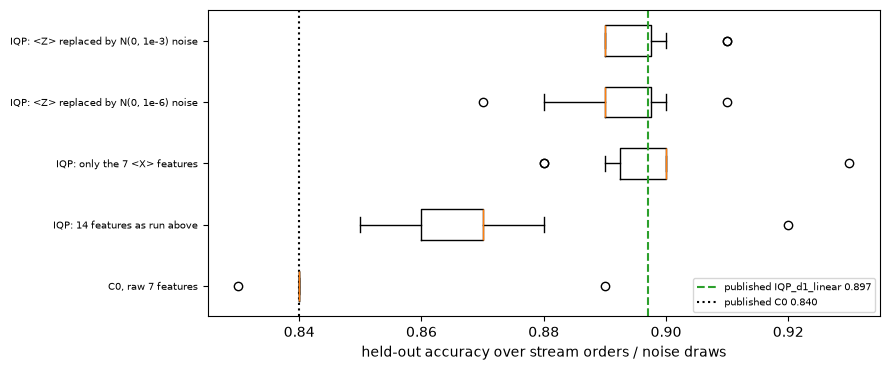

In [22]:
Fm = F_iqp[main]
print(f"{main}: max |<Z_i>| over the {len(Fm)} encoded rows = {np.abs(Fm[:, :7]).max():.2e} (exact value 0); <X_i> ranges over [{Fm[:, 7:].min():.3f}, {Fm[:, 7:].max():.3f}]")
SEEDS_S = range(3 if FAST_MODE else 10)
def accs(F, names, labels=Y_ALL):
    return [float(np.mean(stream_heldout(F, labels, names, s) == labels[HELD])) for s in SEEDS_S]
noise_rng = np.random.default_rng(SEED)
def noisy_z(scale):
    F2 = Fm.astype(float).copy(); F2[:, :7] = noise_rng.normal(0, scale, size=(len(Fm), 7)); return F2
sens = {"C0, raw 7 features": accs(X01, N7),
        f"{main}, 14 features as run above": accs(Fm, N14),
        f"{main}, only the 7 <X> features": accs(Fm[:, 7:], N14[7:]),
        f"{main}, <Z> replaced by N(0, 1e-6) noise": accs(noisy_z(1e-6), N14),
        f"{main}, <Z> replaced by N(0, 1e-3) noise": accs(noisy_z(1e-3), N14)}
sens_df = pd.DataFrame({k: pd.Series(v) for k, v in sens.items()})
display(pd.DataFrame({"mean": sens_df.mean(), "std": sens_df.std(ddof=0), "min": sens_df.min(), "max": sens_df.max()}).round(3))

ceil = {}
for lab, F in [("raw 7 features", X01), (f"{main} 14 features", Fm)]:
    for mname, mdl in [("RandomForest", RandomForestClassifier(300, random_state=SEED)), ("SVC (rbf)", SVC())]:
        ceil[f"{mname}, {lab}"] = float(mdl.fit(F[DEV], Y_ALL[DEV]).score(F[HELD], Y_ALL[HELD]))
print("classical batch learners fitted on the development rows, scored on the same 100 held-out rows:")
display(pd.Series(ceil, name="held-out accuracy").round(3).to_frame())
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([sens_df[c].values for c in sens_df.columns], vert=False)
ax.set_yticks(range(1, len(sens_df.columns) + 1)); ax.set_yticklabels([c.replace(f"{main}, ", "IQP: ") for c in sens_df.columns])
ax.axvline(0.897, color="tab:green", ls="--", label="published IQP_d1_linear 0.897"); ax.axvline(0.84, color="black", ls=":", label="published C0 0.840")
ax.set_xlabel("held-out accuracy over stream orders / noise draws"); ax.legend(fontsize=7); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

### 4.3 The paper's 5-batch protocol with the corrected code, and the leakage-free protocols

The same encoded features and the same river tree are now evaluated four ways, so the effect of the *protocol* can be separated
from the effect of the *encoding*:

1. **Paper protocol (Algorithm 3 loop)**: one tree, never reset; for each batch $k$ it is updated on every row outside the batch and then scored on batch $k$ (so batches $\ge 2$ were trained on before).
2. **Fold-wise, fresh tree**: for each batch a new tree is trained on the other four batches and scored on the held-out batch.
3. **Prequential, scored before training**: one tree sees the batches in order; each batch is predicted first and learned afterwards (batch 1 meets an empty tree and is excluded). The row-wise prequential accuracy over the whole stream is also reported.
4. **Locked held-out** (section 4): 100 rows never trained on.

Inputs: the 14 IQP features of the first architecture, the 7 raw min-max features (the correction's baseline C0), and, for reference,
the original single walk number (standardised on the training rows of the development set only).

accuracy    f1   auc
protocol                                           inputs                                                     
fold-wise, fresh tree                              corrected IQP_d1_linear (14 features)      80.2  78.5  80.2
                                                   original walk (1 number)                   57.3  44.2  55.5
                                                   raw 7 features (C0)                        82.5  78.7  81.5
paper protocol (persistent tree, rows seen before) corrected IQP_d1_linear (14 features)      84.0  83.0  84.4
                                                   original walk (1 number)                   60.1  51.2  58.9
                                                   raw 7 features (C0)                        86.9  85.8  87.1
prequential, scored before training                corrected IQP_d1_linear (14 features)      78.0  75.7  78.0
                                                   original walk (1 number)                   57.9  41.2  55.7
                                                   raw 7 features (C0)                        83.2  79.3  82.1

row-wise prequential accuracy over the stream after 200 warm-up rows: {'corrected IQP_d1_linear (14 features)': 77.4, 'raw 7 features (C0)': 81.9, 'original walk (1 number)': 56.5}
protocol runs: 47 s


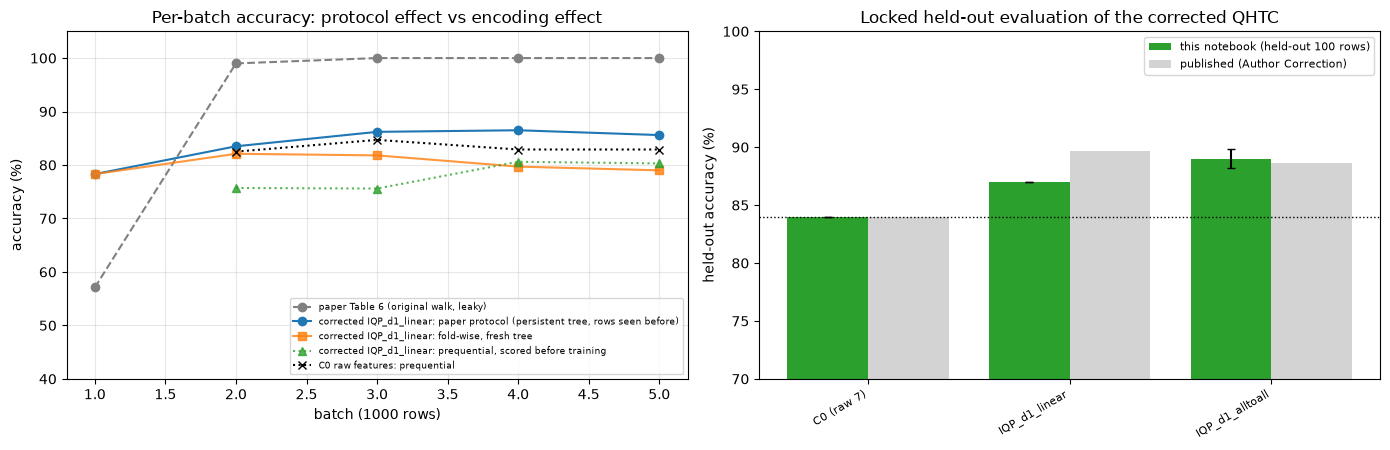

In [23]:
CORR_BATCH = BATCH_SIZE if CORR_ROWS is None else CORR_ROWS // 3
n_b = lock["N"] // CORR_BATCH
batch_idx = [np.arange(k * CORR_BATCH, (k + 1) * CORR_BATCH) for k in range(n_b)]
Xraw_all = corr_csv.iloc[:lock["N"], :7].values.astype(float)
std_dev = StandardScaler().fit(Xraw_all[DEV])
W_all = quantum_walk_closed_form(std_dev.transform(Xraw_all))[:, None]            # the original walk, scaler fitted on the development rows only

def new_tree():
    return river_tree.HoeffdingTreeClassifier(**HP)

def learn(t, F, names, idx, labels, seed):
    order = np.random.default_rng(seed).permutation(idx)
    for i in order:
        t.learn_one(dict(zip(names, map(float, F[i]))), int(labels[i]))

def predict(t, F, names, idx):
    return np.array([(lambda p: 0 if p is None else int(p))(t.predict_one(dict(zip(names, map(float, F[i]))))) for i in idx])

def protocols(F, names, label):
    out, y = [], Y_ALL
    # 1) paper protocol: persistent tree, train on every other batch, test on the batch
    t = new_tree()
    for k, te in enumerate(batch_idx, start=1):
        tr = np.setdiff1d(np.arange(n_b * CORR_BATCH), te)
        learn(t, F, names, tr, y, SEED + k)
        out.append(dict(inputs=label, protocol="paper protocol (persistent tree, rows seen before)", batch=k, **hard_metrics(y[te], predict(t, F, names, te))))
    # 2) fold-wise with a fresh tree
    for k, te in enumerate(batch_idx, start=1):
        tr = np.setdiff1d(np.arange(n_b * CORR_BATCH), te)
        t = new_tree(); learn(t, F, names, tr, y, SEED + k)
        out.append(dict(inputs=label, protocol="fold-wise, fresh tree", batch=k, **hard_metrics(y[te], predict(t, F, names, te))))
    # 3) prequential by batch, scored before training; and row-wise test-then-train
    t = new_tree(); hits = []
    for k, te in enumerate(batch_idx, start=1):
        if k > 1:
            out.append(dict(inputs=label, protocol="prequential, scored before training", batch=k, **hard_metrics(y[te], predict(t, F, names, te))))
        learn(t, F, names, te, y, SEED + k)
    t = new_tree()
    for i in range(n_b * CORR_BATCH):
        d = dict(zip(names, map(float, F[i]))); p = t.predict_one(d); hits.append(int(p == y[i])); t.learn_one(d, int(y[i]))
    return out, float(np.mean(hits[200:]))

t0 = time.perf_counter()
proto_rows, rowwise = [], {}
for label, F, names in [(f"corrected {main} (14 features)", F_iqp[main], N14), ("raw 7 features (C0)", X01, N7), ("original walk (1 number)", W_all, ["walk"])]:
    o, rw = protocols(F, names, label); proto_rows += o; rowwise[label] = rw
corr_protocols = pd.DataFrame(proto_rows)
summ = (corr_protocols.groupby(["protocol", "inputs"])[["accuracy", "f1", "auc"]].mean() * 100).round(1)
display(summ)
print("row-wise prequential accuracy over the stream after 200 warm-up rows:", {k: round(100 * v, 1) for k, v in rowwise.items()})
print(f"protocol runs: {time.perf_counter()-t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
ax.plot(PAPER_TABLE6.index[:n_b], PAPER_TABLE6.accuracy[:n_b], "o--", color="gray", label="paper Table 6 (original walk, leaky)")
styles = {"paper protocol (persistent tree, rows seen before)": ("o-", 1.0), "fold-wise, fresh tree": ("s-", 0.8), "prequential, scored before training": ("^:", 0.8)}
for proto, (st, al) in styles.items():
    d = corr_protocols[(corr_protocols.protocol == proto) & (corr_protocols.inputs == f"corrected {main} (14 features)")]
    ax.plot(d.batch, 100 * d.accuracy, st, alpha=al, label=f"corrected {main}: {proto}")
d = corr_protocols[(corr_protocols.protocol == "prequential, scored before training") & (corr_protocols.inputs == "raw 7 features (C0)")]
ax.plot(d.batch, 100 * d.accuracy, "x:", color="black", label="C0 raw features: prequential")
ax.set_xlabel(f"batch ({CORR_BATCH} rows)"); ax.set_ylabel("accuracy (%)"); ax.set_ylim(40, 105); ax.grid(alpha=0.3); ax.legend(fontsize=6.5, loc="lower right")
ax.set_title("Per-batch accuracy: protocol effect vs encoding effect")
ax = axes[1]
names_ = ["C0 (raw 7)"] + [r["name"] for r in corr_results]
vals = [100 * c0_stream["real_held_mean"]] + [100 * r["real_held_mean"] for r in corr_results]
errs = [100 * c0_stream["real_held_std"]] + [100 * r["real_held_std"] for r in corr_results]
pubv = [84.0] + [100 * pub.set_index("name").loc[r["name"]].real_held_mean for r in corr_results]
xs = np.arange(len(names_))
ax.bar(xs - 0.2, vals, 0.4, yerr=errs, color="tab:green", label="this notebook (held-out 100 rows)", capsize=3)
ax.bar(xs + 0.2, pubv, 0.4, color="lightgray", label="published (Author Correction)")
ax.axhline(100 * c0_stream["real_held_mean"], color="black", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(names_, rotation=30, ha="right", fontsize=8); ax.set_ylim(70, 100); ax.set_ylabel("held-out accuracy (%)"); ax.legend(fontsize=8)
ax.set_title("Locked held-out evaluation of the corrected QHTC")
plt.tight_layout(); plt.show()

## 5. The five hybrid quantum binary classifiers on the 1000-sample file (Table 5, Aer rows), with the settings of the authors' `azure/` notebooks

The paper's Table 5 lists five known classifiers on 1000 rows. Their notebooks fix the recipe, and this section follows it:

* **VQC** (`Paper05_VQC.ipynb`): `train_test_split(train_size=700, test_size=300, random_state=7)` on the raw (**unscaled**) features, the training and test points ordered class by class (benign first), labels benign $=+1$, DGA $=-1$; `ZFeatureMap(7, reps=1)` + `RealAmplitudes(7, reps=1, entanglement="pairwise")`; `VQC(..., loss="cross_entropy", optimizer=COBYLA())` on the qasm simulator (1024 shots). The same notebook also contains a hand-written training loop (cell 17 of the notebook) with the same circuit, a **full bit-string parity** read-out, the cross-entropy summed over the 700 points, `COBYLA()` and 1024 shots; it reports a training accuracy of 0.699. Both are run.
* **QSVC** (`Paper07_QSVC.ipynb`) and **PegasosQSVC** (`Paper06_Pegasos.ipynb`): features scaled with `MinMaxScaler((0, pi))` **fitted on all 1000 rows**, then the first 700 rows train and the last 300 test (`shuffle=False`); `ZFeatureMap(7, reps=1)` fidelity kernel; QSVC with its default $C$, Pegasos with $C = 1000$ and 100 steps, its kernel evaluated on the qasm simulator with 1024 shots.
* **SamplerQNN** (`Paper03_QNN_Sampler.ipynb`) and **EstimatorQNN** (`Paper04_QNN_Estimator.ipynb`): `ZZFeatureMap(7)` + `RealAmplitudes(7, reps=1)` (parity read-out, two classes) and `ZZFeatureMap(7)` + `RealAmplitudes(7)` (expectation of $Z^{\otimes 7}$), `NeuralNetworkClassifier(..., optimizer=SPSA())`, `algorithm_globals.random_seed = 42`. In both notebooks the botnet CSV is loaded and the very next cell **overwrites it with 50 random synthetic points** labelled by the sign of their sum; the score is computed on those same 50 points.

Before any quantum model, classical baselines are trained on exactly the same inputs. Because 300 test rows make every metric noisy (standard
error about 2.5 points), the cheap models are repeated on `N_SEEDS` shuffled splits as well.

In [24]:
df_h    = df1000.iloc[:N_HQBC].reset_index(drop=True)
X_h     = df_h[FEATURES].values.astype(float)
y_h     = df_h["Result"].values.astype(int)                    # 1 = dga (the positive class of every metric below)
n_tr, n_te = TRAIN_SIZE, len(y_h) - TRAIN_SIZE

# (a) kernel-method split of Paper06/Paper07: scaler fitted on ALL rows, first n_tr rows train, rest test (shuffle=False)
sc_all = MinMaxScaler((0, np.pi)).fit(X_h)
SPL_K  = dict(name="kernel split (Paper06/07)", Xtr=sc_all.transform(X_h[:n_tr]), Xte=sc_all.transform(X_h[n_tr:]), ytr=y_h[:n_tr], yte=y_h[n_tr:])
# (b) the same split with the scaler fitted on the training rows only (leakage-free variant, # CHOICE)
sc_tr  = MinMaxScaler((0, np.pi)).fit(X_h[:n_tr])
SPL_KT = dict(name="kernel split, train-only scaler", Xtr=sc_tr.transform(X_h[:n_tr]), Xte=np.clip(sc_tr.transform(X_h[n_tr:]), 0, np.pi), ytr=y_h[:n_tr], yte=y_h[n_tr:])
# (c) VQC split of Paper05: random_state=7, raw features, points ordered class by class (benign first)
s_tr, s_te, l_tr, l_te = train_test_split(X_h, y_h, train_size=n_tr, test_size=n_te, random_state=AZ_SPLIT_SEED)
def class_sorted(S, L):
    o = np.concatenate([np.where(L == 0)[0], np.where(L == 1)[0]])
    return S[o], L[o]
vXtr, vytr = class_sorted(s_tr, l_tr); vXte, vyte = class_sorted(s_te, l_te)
SPL_V  = dict(name="VQC split (Paper05, random_state=7, unscaled)", Xtr=vXtr, Xte=vXte, ytr=vytr, yte=vyte)
for s in (SPL_K, SPL_KT, SPL_V):
    print(f"{s['name']:52s}: {len(s['ytr'])} training rows ({100*s['ytr'].mean():.0f} % DGA), {len(s['yte'])} test rows ({100*s['yte'].mean():.0f} % DGA)")

def dga_metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

results = {}          # model name -> dict(metrics, y_true, y_pred, timings)
repeat_rows = []      # cheap models on repeated splits

def record(name, inputs, split, y_pred, t_fit, t_pred, extra=None, quiet=False):
    r = dict(model=name, inputs=inputs, split=split["name"], n_train=len(split["ytr"]), n_test=len(split["yte"]), fit_s=t_fit, predict_s=t_pred,
             y_true=split["yte"], y_pred=np.asarray(y_pred, dtype=int), **dga_metrics(split["yte"], y_pred))
    r.update(extra or {})
    results[name] = r
    if not quiet:
        report([name])

def report(names):
    for name in names:
        r = results[name]
        extra = f" | {r['evaluations']} evaluations, train acc {100*r['train_accuracy']:.1f} %" if "evaluations" in r else ""
        print(f"{name:58s} accuracy {100*r['accuracy']:5.1f} % | precision {100*r['precision']:5.1f} % | recall {100*r['recall']:5.1f} % | "
              f"F1 {100*r['f1']:5.1f} % | fit {r['fit_s']:7.1f} s{extra}")

def classical_models():
    return {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),
            "SVC (rbf)": SVC(kernel="rbf", C=1.0, random_state=SEED),
            "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
            "DecisionTree": DecisionTreeClassifier(random_state=SEED)}

# classical baselines on exactly the inputs of the kernel split and of the VQC split
for split, tag in [(SPL_K, "kernel split"), (SPL_V, "VQC split")]:
    sc = StandardScaler().fit(split["Xtr"]) if split is SPL_V else None       # SVC / logistic regression need standardised inputs on the raw VQC data
    for mname, model in classical_models().items():
        Xtr, Xte = (sc.transform(split["Xtr"]), sc.transform(split["Xte"])) if (sc is not None and mname in ("SVC (rbf)", "LogisticRegression")) else (split["Xtr"], split["Xte"])
        t0 = time.perf_counter(); model.fit(Xtr, split["ytr"]); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = model.predict(Xte); t_pred = time.perf_counter() - t0
        record(f"{mname} [{tag}]", "7 features, " + ("in [0, pi]" if split is SPL_K else "raw"), split, pred, t_fit, t_pred, quiet=True)
report([n for n in results])

# repeated shuffled splits (train-only scaler) for the cheap models, mean +- std
def make_split(seed):
    tr, te = train_test_split(np.arange(len(y_h)), train_size=n_tr, stratify=y_h, random_state=seed)
    sc = MinMaxScaler((0, np.pi)).fit(X_h[tr])
    return dict(name=f"shuffled {seed}", Xtr=sc.transform(X_h[tr]), Xte=np.clip(sc.transform(X_h[te]), 0, np.pi), ytr=y_h[tr], yte=y_h[te])
for s in range(N_SEEDS):
    d = SPL_KT if s == 0 else make_split(SEED + s)
    for mname, model in classical_models().items():
        pred = model.fit(d["Xtr"], d["ytr"]).predict(d["Xte"])
        repeat_rows.append(dict(model=mname, split=s, **dga_metrics(d["yte"], pred)))

kernel split (Paper06/07)                           : 700 training rows (43 % DGA), 300 test rows (48 % DGA)
kernel split, train-only scaler                     : 700 training rows (43 % DGA), 300 test rows (48 % DGA)
VQC split (Paper05, random_state=7, unscaled)       : 700 training rows (45 % DGA), 300 test rows (45 % DGA)


RandomForest [kernel split]                                accuracy  89.7 % | precision  93.8 % | recall  84.1 % | F1  88.7 % | fit     1.3 s
SVC (rbf) [kernel split]                                   accuracy  85.0 % | precision  92.4 % | recall  75.2 % | F1  82.9 % | fit     0.0 s
LogisticRegression [kernel split]                          accuracy  86.3 % | precision  95.6 % | recall  75.2 % | F1  84.2 % | fit     0.0 s
DecisionTree [kernel split]                                accuracy  89.3 % | precision  93.1 % | recall  84.1 % | F1  88.4 % | fit     0.0 s
RandomForest [VQC split]                                   accuracy  92.7 % | precision  91.2 % | recall  92.6 % | F1  91.9 % | fit     1.3 s
SVC (rbf) [VQC split]                                      accuracy  90.0 % | precision  92.0 % | recall  85.2 % | F1  88.5 % | fit     0.0 s
LogisticRegression [VQC split]                             accuracy  91.3 % | precision  97.4 % | recall  83.0 % | F1  89.6 % | fit     0.0 s
Decisi

### 5.1 Kernel methods: QSVC and PegasosQSVC

Both use the fidelity kernel $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$ of the 7-qubit `ZFeatureMap`. `QSVC` is
scikit-learn's SVC with that kernel matrix (the authors' `FidelityQuantumKernel`; evaluated here exactly on statevectors, the
shot-free limit of their simulator); `PegasosQSVC` is the Pegasos stochastic sub-gradient solver with the authors' $C = 1000$ and 100
steps, run with a kernel whose entries are estimated from 1024 shots (compute-uncompute on the Aer sampler, as the authors' qasm
kernel) and, for comparison, with the exact kernel. Because the `ZFeatureMap` state is a product state, the kernel is simply
$\prod_i \cos^2(x_i - x'_i)$, which is worth knowing when reading the critical section.

In [25]:
qk_exact = FidelityStatevectorKernel(feature_map=FM_Z)
qk_shots = FidelityQuantumKernel(feature_map=FM_Z, fidelity=ComputeUncompute(sampler=AerSampler(default_shots=SHOTS, seed=SEED)))

# sanity check of the product-state closed form on two training rows
a, b = SPL_K["Xtr"][0], SPL_K["Xtr"][1]
print(f"kernel(x0, x1): Qiskit {qk_exact.evaluate(a[None], b[None])[0, 0]:.6f} | closed form prod cos^2(x_i - x'_i) = {np.prod(np.cos(a - b) ** 2):.6f}")

for split, tag in [(SPL_K, "authors' protocol: scaler on all rows"), (SPL_KT, "train-only scaler")]:
    t0 = time.perf_counter(); qsvc = QSVC(quantum_kernel=qk_exact); qsvc.fit(split["Xtr"], split["ytr"]); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = qsvc.predict(split["Xte"]); t_pred = time.perf_counter() - t0
    record(f"QSVC ({tag})", "7 features in [0, pi]", split, pred, t_fit, t_pred)

t0 = time.perf_counter(); peg = PegasosQSVC(quantum_kernel=qk_shots, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED); peg.fit(SPL_K["Xtr"], SPL_K["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = peg.predict(SPL_K["Xte"]); t_pred = time.perf_counter() - t0
record("PegasosQSVC, 1024-shot kernel (authors' protocol: scaler on all rows)", "7 features in [0, pi]", SPL_K, pred, t_fit, t_pred)
t0 = time.perf_counter(); peg = PegasosQSVC(quantum_kernel=qk_exact, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED); peg.fit(SPL_KT["Xtr"], SPL_KT["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = peg.predict(SPL_KT["Xte"]); t_pred = time.perf_counter() - t0
record("PegasosQSVC, exact kernel (train-only scaler)", "7 features in [0, pi]", SPL_KT, pred, t_fit, t_pred)
t0 = time.perf_counter(); peg = PegasosQSVC(quantum_kernel=qk_exact, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED); peg.fit(SPL_K["Xtr"], SPL_K["ytr"]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = peg.predict(SPL_K["Xte"]); t_pred = time.perf_counter() - t0
record("PegasosQSVC, exact kernel (authors' protocol: scaler on all rows)", "7 features in [0, pi]", SPL_K, pred, t_fit, t_pred)

# repeated splits (the authors' Paper06 also averages ten Pegasos runs: 0.739 there, single run 0.823)
for s in range(N_SEEDS):
    d = SPL_KT if s == 0 else make_split(SEED + s)
    for name, model in [("QSVC (train-only scaler)", QSVC(quantum_kernel=qk_exact)),
                        ("PegasosQSVC, exact kernel (train-only scaler)", PegasosQSVC(quantum_kernel=qk_exact, C=PEGASOS_C, num_steps=PEGASOS_STEPS, seed=SEED + s))]:
        pred = model.fit(d["Xtr"], d["ytr"]).predict(d["Xte"])
        repeat_rows.append(dict(model=name, split=s, **dga_metrics(d["yte"], pred)))
rep = pd.DataFrame(repeat_rows).groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]) * 100
print(f"\nmean +- std over {N_SEEDS} splits (first split + {N_SEEDS-1} shuffled), in %:")
display(rep.round(1))

kernel(x0, x1): Qiskit 0.337558 | closed form prod cos^2(x_i - x'_i) = 0.337558


QSVC (authors' protocol: scaler on all rows)               accuracy  86.3 % | precision  93.3 % | recall  77.2 % | F1  84.5 % | fit    17.9 s


QSVC (train-only scaler)                                   accuracy  86.3 % | precision  93.3 % | recall  77.2 % | F1  84.5 % | fit    19.7 s


PegasosQSVC, 1024-shot kernel (authors' protocol: scaler on all rows) accuracy  79.0 % | precision  84.7 % | recall  69.0 % | F1  76.0 % | fit   100.5 s


PegasosQSVC, exact kernel (train-only scaler)              accuracy  77.3 % | precision  84.7 % | recall  64.8 % | F1  73.4 % | fit     9.1 s


PegasosQSVC, exact kernel (authors' protocol: scaler on all rows) accuracy  77.3 % | precision  84.7 % | recall  64.8 % | F1  73.4 % | fit     8.3 s



mean +- std over 3 splits (first split + 2 shuffled), in %:


accuracy         f1     
                                                  mean  std  mean  std
model                                                                 
DecisionTree                                      90.4  1.9  89.4  2.2
LogisticRegression                                88.0  1.7  85.9  1.8
PegasosQSVC, exact kernel (train-only scaler)     80.2  2.7  77.8  4.1
QSVC (train-only scaler)                          89.9  3.1  88.5  3.5
RandomForest                                      91.3  1.7  90.4  1.7
SVC (rbf)                                         88.4  3.0  86.7  3.3

### 5.2 VQC: the library `VQC` and the hand-written loop of `Paper05`

The first model is the library `VQC` of `Paper05` (cells 12-14): `ZFeatureMap(7, reps=1)` composed with `RealAmplitudes(7, reps=1,
entanglement="pairwise")` (14 trainable angles), cross-entropy, `COBYLA`. Two details of the authors' notebook matter for the result: the
features are fed **unscaled** (a `CharLength` of 30 becomes a rotation of 60 rad, a reputation of 200 a rotation of 400 rad), and the labels
are $\pm 1$ with benign $= +1$. The second model is the hand-written loop of cells 17-19: the probability of class "1" (benign) is the
probability of an odd number of 1s in the measured bit string, the loss is the cross-entropy **summed** over the training points with a
$10^{-10}$ cutoff on the logarithm, and the optimiser is `COBYLA` from a random start. The loss curves are redrawn every ten evaluations.
The optimiser budget is `VQC_MAXITER` evaluations; the authors' `COBYLA()` allows 1000 and their hand-written loop made 131,600 circuit
executions.

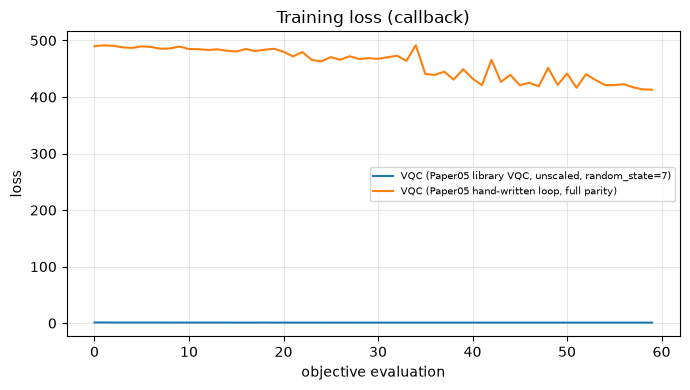

VQC (Paper05 library VQC, unscaled, random_state=7)        accuracy  62.7 % | precision  60.2 % | recall  50.4 % | F1  54.8 % | fit   727.6 s | 60 evaluations, train acc 60.0 %
VQC (Paper05 hand-written loop, full parity)               accuracy  66.0 % | precision  69.0 % | recall  44.4 % | F1  54.1 % | fit   707.4 s | 60 evaluations, train acc 70.6 %
authors' notebook output (Paper05): library VQC test 0.633 / train 0.606; hand-written loop train 0.699 (test not printed); paper Table 5: 54 %


In [26]:
loss_curves = {}

def draw_losses():
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    for key, losses in loss_curves.items():
        ax.plot(losses, label=key)
    ax.set_xlabel("objective evaluation"); ax.set_ylabel("loss"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax.set_title("Training loss (callback)"); plt.tight_layout(); plt.show()

def make_callback(key):
    loss_curves[key] = []
    def cb(*args):                                   # COBYLA path: (weights, loss); the SPSA path of qiskit-machine-learning 0.9 passes (nfev, x, fx, step, accepted)
        loss_curves[key].append(float(args[-1] if len(args) == 2 else args[2]))
        if len(loss_curves[key]) % 10 == 0:
            draw_losses()
    return cb

# --- the library VQC exactly as Paper05 cells 12-14 ---
pm_tr = np.where(SPL_V["ytr"] == 1, -1, 1)           # benign +1, dga -1, as in Paper05
key_vqc = "VQC (Paper05 library VQC, unscaled, random_state=7)"
algorithm_globals.random_seed = SEED
vqc = VQC(feature_map=FM_Z, ansatz=ANS_VQC, loss="cross_entropy", optimizer=COBYLA(maxiter=VQC_MAXITER),
          sampler=AerSampler(default_shots=SHOTS, seed=SEED), callback=make_callback(key_vqc))
assert vqc.neural_network.circuit.decompose(reps=3).count_ops() == compose(FM_Z, ANS_VQC).decompose(reps=3).count_ops(), "the trained circuit differs from the drawn one"
t0 = time.perf_counter(); vqc.fit(SPL_V["Xtr"], pm_tr); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred_pm = np.asarray(vqc.predict(SPL_V["Xte"])).ravel(); t_pred = time.perf_counter() - t0
train_acc = float(np.mean(np.asarray(vqc.predict(SPL_V["Xtr"])).ravel() == pm_tr))
record(key_vqc, "7 raw features", SPL_V, (pred_pm == -1).astype(int), t_fit, t_pred, dict(evaluations=len(loss_curves[key_vqc]), train_accuracy=train_acc), quiet=True)

# --- the hand-written loop of Paper05 cells 17-19 (one Aer call per objective evaluation instead of one per point) ---
circ_hand = compose(FM_Z, ANS_VQC, measure=True)
order = list(circ_hand.parameters)
fm_ix, w_ix = {p: i for i, p in enumerate(FM_Z.parameters)}, {p: i for i, p in enumerate(ANS_VQC.parameters)}
hand_sampler = AerSampler(default_shots=SHOTS, seed=SEED)
def p_odd(theta, X):
    """Probability of an odd number of 1s in the measured bit string, one row of the parameter table per point."""
    M = np.empty((len(X), len(order)))
    for j, p in enumerate(order):
        M[:, j] = X[:, fm_ix[p]] if p in fm_ix else theta[w_ix[p]]
    bits = hand_sampler.run([(circ_hand, M)]).result()[0].data.meas.array            # (points, shots, bytes)
    return (np.unpackbits(bits, axis=-1).sum(-1) % 2).mean(axis=1)
CUT = 1e-10
y1_tr = ((1 + pm_tr) / 2)                                                              # benign = 1, as in Paper05 (one_zero_labels)
key_hand = "VQC (Paper05 hand-written loop, full parity)"
loss_curves[key_hand] = []
def hand_loss(theta):
    p = p_odd(theta, SPL_V["Xtr"])
    val = float(-np.sum(y1_tr * np.log(np.maximum(CUT, p)) + (1 - y1_tr) * np.log(np.maximum(CUT, 1 - p))))
    loss_curves[key_hand].append(val)
    if len(loss_curves[key_hand]) % 10 == 0:
        draw_losses()
    return val
t0 = time.perf_counter()
res_hand = COBYLA(maxiter=VQC_HAND_MAXITER).minimize(hand_loss, x0=rng.random(ANS_VQC.num_parameters))
t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); p_te = p_odd(res_hand.x, SPL_V["Xte"]); t_pred = time.perf_counter() - t0
pred_dga = (p_te <= 0.5).astype(int)                                                    # class "1" = benign when P(odd) > 0.5
train_acc = float(np.mean((p_odd(res_hand.x, SPL_V["Xtr"]) > 0.5) == (y1_tr == 1)))
record(key_hand, "7 raw features", SPL_V, pred_dga, t_fit, t_pred, dict(evaluations=len(loss_curves[key_hand]), train_accuracy=train_acc), quiet=True)
draw_losses()
report([key_vqc, key_hand])
print("authors' notebook output (Paper05): library VQC test 0.633 / train 0.606; hand-written loop train 0.699 (test not printed); paper Table 5: 54 %")

### 5.3 SamplerQNN and EstimatorQNN: what the authors' notebooks scored, and the same networks on botnet rows

First the authors' code path is replayed exactly (`Paper03`, `Paper04`): `algorithm_globals.random_seed = 42`, 50 random points in
$[-1, 1]^7$ labelled by the sign of their sum, `NeuralNetworkClassifier(..., optimizer=SPSA())` with its default 100 iterations, Aer's
sampler/estimator (1024 shots, seeded; the authors used the library's default primitives, which are 5-10 times slower here), and `score(X, y)` on the very points the network was fitted on. Their printed values are 0.74 (SamplerQNN) and
0.80 (EstimatorQNN); Table 5 says 76 % and 84 %. Then the same two networks (same circuits, `SPSA`) are trained on botnet rows of the
kernel split (train-only scaler, the first `QNN_TRAIN_ROWS` training rows, `# CHOICE`: cost control) and scored on the 300 test rows.

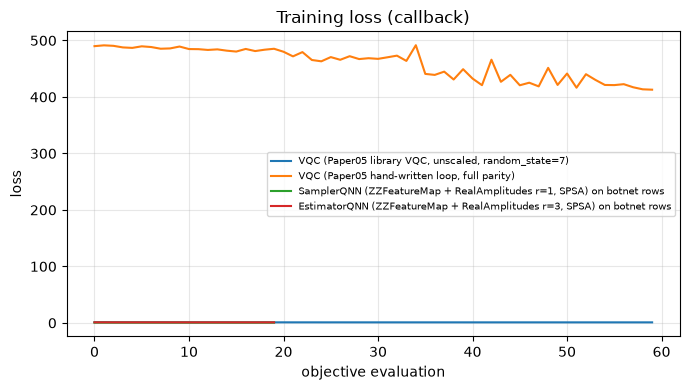

SamplerQNN (ZZFeatureMap + RealAmplitudes r=1, SPSA) on botnet rows accuracy  54.0 % | precision  52.2 % | recall  57.2 % | F1  54.6 % | fit   318.4 s | 20 evaluations, train acc 64.7 %
EstimatorQNN (ZZFeatureMap + RealAmplitudes r=3, SPSA) on botnet rows accuracy  57.3 % | precision  55.6 % | recall  58.6 % | F1  57.0 % | fit    48.5 s | 20 evaluations, train acc 62.7 %


In [27]:
def parity(x):
    return bin(x).count("1") % 2          # Paper03: "{:b}".format(x).count("1") % 2

def build_sampler_qnn(sampler):
    qc = compose(FM_ZZ, ANS_SAMPLER)
    return SamplerQNN(circuit=qc, input_params=FM_ZZ.parameters, weight_params=ANS_SAMPLER.parameters, interpret=parity, output_shape=2, sampler=sampler)

def build_estimator_qnn():
    qc = compose(FM_ZZ, ANS_ESTIMATOR)
    return EstimatorQNN(circuit=qc, input_params=FM_ZZ.parameters, weight_params=ANS_ESTIMATOR.parameters,
                        estimator=AerEstimator(options={"run_options": {"shots": SHOTS, "seed_simulator": SEED}}))      # CHOICE: Aer primitive instead of the library default

# ---- 1) the authors' code path: 50 synthetic points, SPSA(), score on the training points ----
toy = {}
for name in ("SamplerQNN", "EstimatorQNN"):
    algorithm_globals.random_seed = 42                                    # Paper03/04
    X_toy = 2 * algorithm_globals.random.random([50, N_QUBITS]) - 1
    y01 = 1 * (np.sum(X_toy, axis=1) >= 0)
    labels = y01 if name == "SamplerQNN" else 2 * y01 - 1
    qnn = build_sampler_qnn(AerSampler(default_shots=SHOTS, seed=SEED)) if name == "SamplerQNN" else build_estimator_qnn()
    clf = NeuralNetworkClassifier(qnn, optimizer=SPSA(maxiter=SPSA_MAXITER_TOY))
    t0 = time.perf_counter(); clf.fit(X_toy, labels); t = time.perf_counter() - t0
    toy[name] = dict(train_score=float(clf.score(X_toy, labels)), seconds=t)
    print(f"{name} on the 50 synthetic points, scored on its own training set: {100*toy[name]['train_score']:.0f} % in {t:.0f} s"
          f"   (authors' notebook: {'74' if name == 'SamplerQNN' else '80'} %, paper Table 5: {'76' if name == 'SamplerQNN' else '84'} %)")
print("Neither number says anything about DGA detection: no botnet row was used.")

# ---- 2) the same networks on botnet rows ----
qtr = slice(0, min(QNN_TRAIN_ROWS, len(SPL_KT["ytr"])))
Xq, yq = SPL_KT["Xtr"][qtr], SPL_KT["ytr"][qtr]
key = "SamplerQNN (ZZFeatureMap + RealAmplitudes r=1, SPSA) on botnet rows"
algorithm_globals.random_seed = 42
clf = NeuralNetworkClassifier(build_sampler_qnn(AerSampler(default_shots=SHOTS, seed=SEED)), optimizer=SPSA(maxiter=SPSA_MAXITER_BOTNET), callback=make_callback(key))
t0 = time.perf_counter(); clf.fit(Xq, yq); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = np.asarray(clf.predict(SPL_KT["Xte"])).ravel().astype(int); t_pred = time.perf_counter() - t0
record(key, "7 features in [0, pi]", SPL_KT, pred, t_fit, t_pred, dict(evaluations=len(loss_curves[key]), train_accuracy=float(clf.score(Xq, yq))), quiet=True)

key = "EstimatorQNN (ZZFeatureMap + RealAmplitudes r=3, SPSA) on botnet rows"
algorithm_globals.random_seed = 42
clf = NeuralNetworkClassifier(build_estimator_qnn(), optimizer=SPSA(maxiter=SPSA_MAXITER_BOTNET), callback=make_callback(key))
t0 = time.perf_counter(); clf.fit(Xq, 2 * yq - 1); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pred = (np.asarray(clf.predict(SPL_KT["Xte"])).ravel() > 0).astype(int); t_pred = time.perf_counter() - t0
record(key, "7 features in [0, pi]", SPL_KT, pred, t_fit, t_pred, dict(evaluations=len(loss_curves[key]), train_accuracy=float(clf.score(Xq, 2 * yq - 1))), quiet=True)
draw_losses()
report([k for k in results if "QNN" in k])

## 6. Metrics, confusion matrices and timings

DGA (class 1) is the positive class. The confusion matrices show the test rows of each model's own split; the top-right cell
is a DGA name let through, the bottom-left a legitimate name blocked. Wall-clock times are on this machine's CPU with a shot-based
Aer simulator and are comparable only with each other.

Test metrics (300 test rows per model):


,split,accuracy %,precision %,recall %,F1 %,train acc %,evaluations,fit s,predict s
model,,,,,,,,,
RandomForest [kernel split],kernel split (Paper06/07),89.7,93.8,84.1,88.7,NaN,NaN,1.3,0.07
SVC (rbf) [kernel split],kernel split (Paper06/07),85.0,92.4,75.2,82.9,NaN,NaN,0.0,0.01
LogisticRegression [kernel split],kernel split (Paper06/07),86.3,95.6,75.2,84.2,NaN,NaN,0.0,0.00
DecisionTree [kernel split],kernel split (Paper06/07),89.3,93.1,84.1,88.4,NaN,NaN,0.0,0.00
RandomForest [VQC split],"VQC split (Paper05, random_state=7, unscaled)",92.7,91.2,92.6,91.9,NaN,NaN,1.3,0.07
SVC (rbf) [VQC split],"VQC split (Paper05, random_state=7, unscaled)",90.0,92.0,85.2,88.5,NaN,NaN,0.0,0.02
LogisticRegression [VQC split],"VQC split (Paper05, random_state=7, unscaled)",91.3,97.4,83.0,89.6,NaN,NaN,0.0,0.00
DecisionTree [VQC split],"VQC split (Paper05, random_state=7, unscaled)",90.7,89.6,89.6,89.6,NaN,NaN,0.0,0.00
QSVC (authors' protocol: scaler on all rows),kernel split (Paper06/07),86.3,93.3,77.2,84.5,NaN,NaN,17.9,10.26


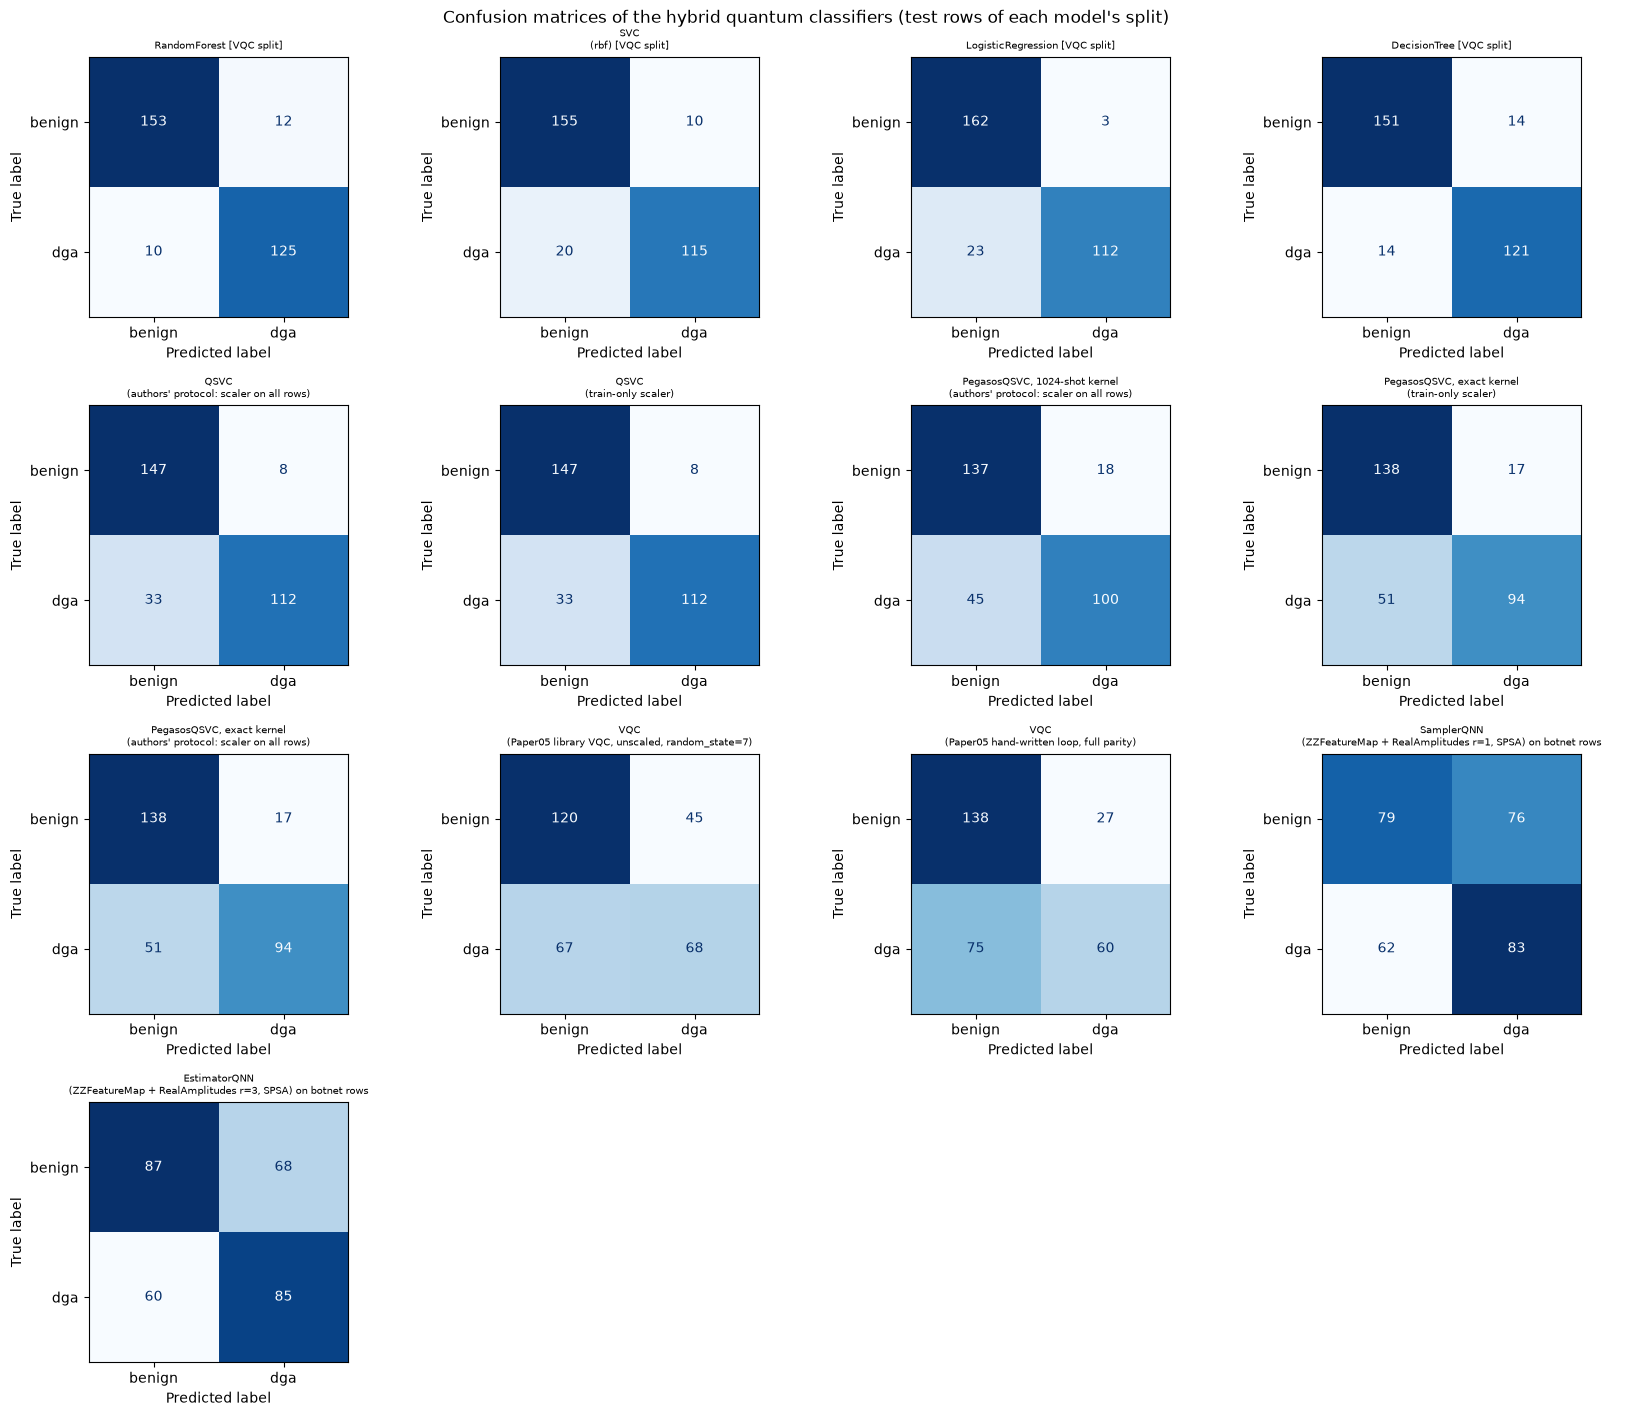

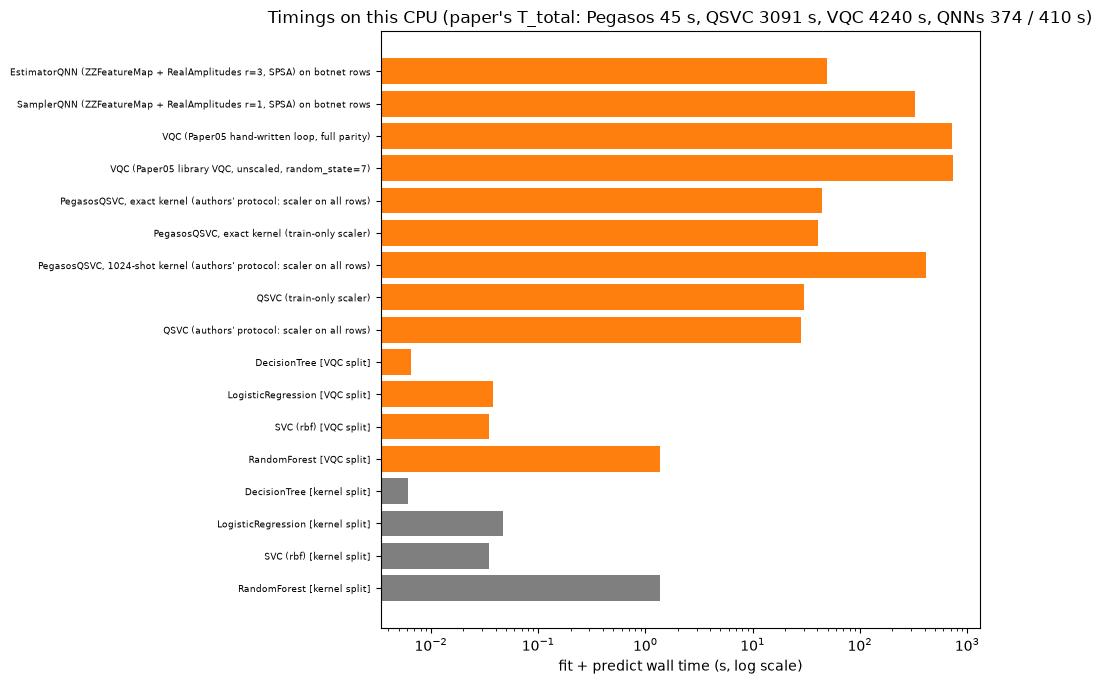

In [28]:
table5 = pd.DataFrame([{"model": n, "split": r["split"], "accuracy %": round(100 * r["accuracy"], 1), "precision %": round(100 * r["precision"], 1),
                        "recall %": round(100 * r["recall"], 1), "F1 %": round(100 * r["f1"], 1), "train acc %": round(100 * r["train_accuracy"], 1) if "train_accuracy" in r else np.nan,
                        "evaluations": r.get("evaluations", np.nan), "fit s": round(r["fit_s"], 1), "predict s": round(r["predict_s"], 2)} for n, r in results.items()])
print(f"Test metrics ({n_te} test rows per model):")
pd.set_option("display.max_colwidth", 70)
display(table5.set_index("model"))

quantum_names = [n for n in results if any(s in n for s in ("QSVC", "Pegasos", "VQC", "QNN"))]
cols = 4; nrows = int(np.ceil(len(quantum_names) / cols))
fig, axes = plt.subplots(nrows, cols, figsize=(4.2 * cols, 3.6 * nrows))
for ax, name in zip(axes.ravel(), quantum_names):
    cm = confusion_matrix(results[name]["y_true"], results[name]["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["benign", "dga"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(" (", "\n("), fontsize=7)
for ax in axes.ravel()[len(quantum_names):]:
    ax.axis("off")
plt.suptitle("Confusion matrices of the hybrid quantum classifiers (test rows of each model's split)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 0.32 * len(results) + 1.5))
names = list(results); ax.barh(names, [results[n]["fit_s"] + results[n]["predict_s"] for n in names], color=["tab:orange" if n in quantum_names else "tab:gray" for n in names])
ax.set_xscale("log"); ax.set_xlabel("fit + predict wall time (s, log scale)"); ax.tick_params(axis="y", labelsize=6.5)
ax.set_title("Timings on this CPU (paper's T_total: Pegasos 45 s, QSVC 3091 s, VQC 4240 s, QNNs 374 / 410 s)")
plt.tight_layout(); plt.show()

## 7. Paper versus this notebook

Each row is one number the paper or the Author Correction reports. A claim is **reproduced** when our value lies within 2 accuracy
points (0.02 in F1 / AUC) of the reported one, **not reached** when it is lower by more, **exceeded** when it is higher by more, and
**cannot be checked** when the notebook cannot test it (real devices, cloud emulators, timings on other hardware). For QHTC the rows
are given in three groups: the *original* Table 6 (paper protocol, authors' tree), the *Author Correction's* replacement Table 6
(locked held-out, corrected encoding, corrected tree), and what the corrected encoding gives under the paper's own batch protocol and
under leakage-free protocols.

In [29]:
TOL_ACC, TOL_F1 = 2.0, 2.0     # percentage points

def verdict(paper, ours, tol):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return f"exceeded (+{ours - paper:.1f})" if ours > paper else f"not reached ({ours - paper:.1f})"

def lf(proto, inputs, model="HoeffdingTree (river)"):
    return leakfree[(leakfree.protocol == proto) & (leakfree.inputs == inputs) & (leakfree.model == model)]

rows = []
# --- A. original Table 6 (paper protocol, authors' tree) ---
for k, prow in PAPER_TABLE6.iterrows():
    ours = full_batches[full_batches.batch == k]
    for metric, tol in [("accuracy", TOL_ACC), ("f1", TOL_F1), ("auc", TOL_F1)]:
        o = float(100 * ours[metric].iloc[0]) if len(ours) else np.nan
        rows.append(dict(group="A original Table 6", claim=f"batch {k}, {metric} (paper protocol, authors' tree)", paper=prow[metric], notebook=round(o, 1) if not np.isnan(o) else np.nan,
                         verdict=verdict(prow[metric], o, tol) if len(ours) else f"not run in FAST_MODE ({n_batches} batches)"))
avg_p = {"accuracy": 91.2, "f1": 80.7, "auc": 90.0}
for metric, tol in [("accuracy", TOL_ACC), ("f1", TOL_F1), ("auc", TOL_F1)]:
    o = float(100 * full_batches[metric].mean())
    rows.append(dict(group="A original Table 6", claim=f"average {metric} over the batches (paper protocol, authors' tree)", paper=avg_p[metric], notebook=round(o, 1), verdict=verdict(avg_p[metric], o, tol)))
    o2 = float(100 * lf("fold-wise, fresh tree", "quantum walk (1 number)")[metric].mean())
    rows.append(dict(group="A original Table 6", claim=f"average {metric}: original walk, leakage-free fold-wise river tree", paper=avg_p[metric], notebook=round(o2, 1), verdict=verdict(avg_p[metric], o2, tol)))
o2 = float(100 * lf("fold-wise, fresh tree", "quantum walk (1 number)").accuracy.max())
rows.append(dict(group="A original Table 6", claim="100 % accuracy from the third batch on: original walk, leakage-free, best batch", paper=100.0, notebook=round(o2, 1), verdict=verdict(100.0, o2, TOL_ACC)))
rows.append(dict(group="A original Table 6", claim="QHTC total execution time T_total (Rigetti emulator)", paper=1687.0, notebook=round(t_qiskit + t_qhtc_paper, 0),
                 verdict="cannot be checked (other hardware; our walk is simulated on " + str(n_check) + " rows)"))

# --- B. the Author Correction's replacement Table 6 / Table 5 row ---
pub_i = pub.set_index("name")
rows.append(dict(group="B Author Correction", claim="C0 = river Hoeffding tree on raw 7 features, held-out accuracy", paper=84.0, notebook=round(100 * c0_stream["real_held_mean"], 1),
                 verdict=verdict(84.0, 100 * c0_stream["real_held_mean"], TOL_ACC)))
rows.append(dict(group="B Author Correction", claim="C0 litmus (random-label) held-out accuracy", paper=51.0, notebook=round(100 * c0_stream["litmus_held_mean"], 1),
                 verdict=verdict(51.0, 100 * c0_stream["litmus_held_mean"], 5.0) + " (tolerance 5 points: a 100-row coin flip)"))
for r in corr_results:
    pr = pub_i.loc[r["name"]]
    rows.append(dict(group="B Author Correction", claim=f"{r['name']} held-out accuracy", paper=round(100 * pr.real_held_mean, 1), notebook=round(100 * r["real_held_mean"], 1),
                     verdict=verdict(100 * pr.real_held_mean, 100 * r["real_held_mean"], TOL_ACC)))
    rows.append(dict(group="B Author Correction", claim=f"{r['name']} litmus held-out accuracy", paper=round(100 * pr.litmus_held_mean, 1), notebook=round(100 * r["litmus_held_mean"], 1),
                     verdict=verdict(100 * pr.litmus_held_mean, 100 * r["litmus_held_mean"], 5.0) + " (tolerance 5 points)"))
    rows.append(dict(group="B Author Correction", claim=f"{r['name']} verdict (F1 effect size, F2 litmus, F3 BH-FDR p<0.05)", paper=pr.verdict, notebook=r["verdict"],
                     verdict="reproduced" if r["verdict"] == pr.verdict else f"not reproduced (here {r['verdict']}, BH over the {len(corr_results)} architectures run: p={r['p_value_bh']:.3f})"))
m = corr_results[0]
rows.append(dict(group="B Author Correction", claim="Table 5 row QHTC-Aer: 89.7 % held-out accuracy (IQP_d1_linear)", paper=89.7, notebook=round(100 * m["real_held_mean"], 1),
                 verdict=verdict(89.7, 100 * m["real_held_mean"], TOL_ACC)))
rows.append(dict(group="B Author Correction", claim="Table 5 row QHTC-Aer: encoding wall time (22 vCPU GCE instance)", paper=17.0, notebook=round(m["encode_time_s"], 0),
                 verdict=f"cannot be checked ({ENCODE_WORKERS} workers on this machine)"))
rows.append(dict(group="B Author Correction", claim="improvement over classical HTC, 5.7 points, significant at p_BH<0.05 (3 seeds, IQP_d1_linear)", paper=5.7,
                 notebook=round(100 * (m["real_held_mean"] - c0_stream["real_held_mean"]), 1),
                 verdict=verdict(5.7, 100 * (m["real_held_mean"] - c0_stream["real_held_mean"]), TOL_ACC) + f"; p_BH here {m['p_value_bh']:.3f}; per-row McNemar p (seed 0) see section 4.1"))

rows.append(dict(group="B Author Correction", claim="classical RBF-SVM on raw 7 features, same held-out rows (the correction's own batch-regime log, run 20260510_135952: C0_batch 0.960)",
                 paper=96.0, notebook=round(100 * ceil["SVC (rbf), raw 7 features"], 1), verdict=verdict(96.0, 100 * ceil["SVC (rbf), raw 7 features"], TOL_ACC) + " (a baseline the replacement Table 6 does not show)"))
rows.append(dict(group="B Author Correction", claim=f"{main} held-out accuracy when only the stream order / the numerical noise of the <Z> columns changes (mean over {len(SEEDS_S)} runs)",
                 paper=round(100 * pub_i.loc[main].real_held_mean, 1), notebook=round(100 * sens_df[f"{main}, 14 features as run above"].mean(), 1),
                 verdict=verdict(100 * pub_i.loc[main].real_held_mean, 100 * sens_df[f"{main}, 14 features as run above"].mean(), TOL_ACC) +
                         f"; with N(0,1e-6) noise in the <Z> columns: {100*sens_df[f'{main}, <Z> replaced by N(0, 1e-6) noise'].mean():.1f}"))

# --- C. the corrected encoding under the paper's protocol and under leakage-free protocols ---
cp = corr_protocols[corr_protocols.inputs == f"corrected {main} (14 features)"]
for proto in ["paper protocol (persistent tree, rows seen before)", "fold-wise, fresh tree", "prequential, scored before training"]:
    o = float(100 * cp[cp.protocol == proto].accuracy.mean())
    rows.append(dict(group="C corrected encoding, other protocols", claim=f"{main}: average accuracy, {proto}", paper=91.2, notebook=round(o, 1),
                     verdict=verdict(91.2, o, TOL_ACC) + " vs the paper's 91.2 %"))
    rows.append(dict(group="C corrected encoding, other protocols", claim=f"{main}: average accuracy, {proto}", paper=round(100 * pub_i.loc[main].real_held_mean if main in pub_i.index else np.nan, 1), notebook=round(o, 1),
                     verdict=verdict(100 * pub_i.loc[main].real_held_mean, o, TOL_ACC) + " vs the correction's held-out 0.897"))
o = 100 * rowwise[f"corrected {main} (14 features)"]
rows.append(dict(group="C corrected encoding, other protocols", claim=f"{main}: row-wise prequential accuracy over the stream", paper=89.7, notebook=round(o, 1), verdict=verdict(89.7, o, TOL_ACC) + " vs the correction's 0.897"))
o = 100 * rowwise["raw 7 features (C0)"]
rows.append(dict(group="C corrected encoding, other protocols", claim="C0 (raw features): row-wise prequential accuracy over the stream", paper=84.0, notebook=round(o, 1), verdict=verdict(84.0, o, TOL_ACC) + " vs the correction's 0.840"))

# --- D. Table 5, Aer rows, with the authors' settings ---
def acc(name): return 100 * results[name]["accuracy"]
P5 = {"VQC-Aer (COBYLA), 1000 samples: library VQC, Paper05 settings": (54.0, key_vqc),
      "VQC-Aer: hand-written loop of Paper05 (test accuracy)": (54.0, key_hand),
      "PegasosQSVC-Aer, 1000 samples (1024-shot kernel, authors' protocol)": (90.0, "PegasosQSVC, 1024-shot kernel (authors' protocol: scaler on all rows)"),
      "QSVC-Aer, 1000 samples (authors' protocol)": (87.0, "QSVC (authors' protocol: scaler on all rows)"),
      "SamplerQNN-Aer, 1000 samples (trained on botnet rows here)": (76.0, "SamplerQNN (ZZFeatureMap + RealAmplitudes r=1, SPSA) on botnet rows"),
      "EstimatorQNN-Aer, 1000 samples (trained on botnet rows here)": (84.0, "EstimatorQNN (ZZFeatureMap + RealAmplitudes r=3, SPSA) on botnet rows")}
for claim, (p, name) in P5.items():
    note = "" if N_HQBC >= 1000 else f" [FAST_MODE: {n_tr}/{n_te} rows]"
    note += f" [{results[name].get('evaluations', '')} optimiser evaluations vs the authors' budget]" if "evaluations" in results[name] else ""
    rows.append(dict(group="D Table 5, Aer rows", claim=claim + note, paper=p, notebook=round(acc(name), 1), verdict=verdict(p, acc(name), TOL_ACC)))
for name, p, nt in [("SamplerQNN", 76.0, 74), ("EstimatorQNN", 84.0, 80)]:
    rows.append(dict(group="D Table 5, Aer rows", claim=f"{name}-Aer as the authors' code computes it (50 synthetic points, training score)", paper=p, notebook=round(100 * toy[name]["train_score"], 1),
                     verdict=verdict(p, 100 * toy[name]["train_score"], TOL_ACC) + f" (authors' notebook printed {nt} %; not botnet data)"))
rows.append(dict(group="D Table 5, Aer rows", claim="VQC-Aer by ref. [12] (Suryotrisongko & Musashi 2022), 1000 samples", paper=76.8, notebook=round(acc(key_vqc), 1), verdict="cannot be checked (another paper's run; shown for context)"))
rows.append(dict(group="D Table 5, Aer rows", claim="RandomForest on the same 7 features (kernel split; this notebook's baseline)", paper=np.nan, notebook=round(acc("RandomForest [kernel split]"), 1), verdict="cannot be checked (no paper value)"))
rows.append(dict(group="D Table 5, Aer rows", claim="Table 4: real devices IonQ / Rigetti / Quantinuum, 100 samples (39-59 %)", paper=59.0, notebook=np.nan, verdict="cannot be checked (needs Azure Quantum)"))
rows.append(dict(group="D Table 5, Aer rows", claim="Table 5: IonQ-S / Quantinuum-S / Rigetti-S emulator rows (45-63 %)", paper=63.0, notebook=np.nan, verdict="cannot be checked (needs Azure Quantum)"))
rows.append(dict(group="D Table 5, Aer rows", claim="Table 2 descriptive statistics (means of the 7 features)", paper=np.nan, notebook=np.nan, verdict="consistent with the 5000-row sample (section 1)"))

comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_rows", 200)
display(comparison)
for g, d in comparison.groupby("group"):
    print(f"{g:42s}: {int(d.verdict.str.startswith('reproduced').sum())} reproduced, {int(d.verdict.str.startswith('not').sum())} not reached/not reproduced, "
          f"{int(d.verdict.str.startswith('exceeded').sum())} exceeded, {int(d.verdict.str.startswith('cannot').sum())} cannot be checked")
T_TOTAL = time.perf_counter() - T_NOTEBOOK_START
print(f"\nFAST_MODE = {FAST_MODE}; wall-clock time of the whole notebook on this machine: {T_TOTAL/60:.1f} min")

,group,claim,paper,notebook,verdict
0,A original Table 6,"batch 1, accuracy (paper protocol, authors' tree)",57.1,57.1,reproduced
1,A original Table 6,"batch 1, f1 (paper protocol, authors' tree)",4.5,4.5,reproduced
2,A original Table 6,"batch 1, auc (paper protocol, authors' tree)",51.1,51.1,reproduced
3,A original Table 6,"batch 2, accuracy (paper protocol, authors' tree)",99.0,99.0,reproduced
4,A original Table 6,"batch 2, f1 (paper protocol, authors' tree)",98.8,98.8,reproduced
5,A original Table 6,"batch 2, auc (paper protocol, authors' tree)",98.9,98.9,reproduced
6,A original Table 6,"batch 3, accuracy (paper protocol, authors' tree)",100.0,100.0,reproduced
7,A original Table 6,"batch 3, f1 (paper protocol, authors' tree)",100.0,100.0,reproduced
8,A original Table 6,"batch 3, auc (paper protocol, authors' tree)",100.0,100.0,reproduced
9,A original Table 6,"batch 4, accuracy (paper protocol, authors' tree)",100.0,100.0,reproduced


A original Table 6                        : 18 reproduced, 4 not reached/not reproduced, 0 exceeded, 1 cannot be checked
B Author Correction                       : 7 reproduced, 4 not reached/not reproduced, 1 exceeded, 1 cannot be checked
C corrected encoding, other protocols     : 0 reproduced, 8 not reached/not reproduced, 0 exceeded, 0 cannot be checked
D Table 5, Aer rows                       : 2 reproduced, 4 not reached/not reproduced, 2 exceeded, 4 cannot be checked

FAST_MODE = False; wall-clock time of the whole notebook on this machine: 95.0 min


## Reading the paper critically

All numbers below are from the committed full run (`FAST_MODE = False`); the verdict table in section 7 has the exact values.

### What the Author Correction changes relative to the earlier finding, and what it does not

**The corrected repository contains no repaired version of the paper's tree class.** It replaces both halves of the original QHTC.
* *Does the corrected tree reset?* Every run builds a fresh `river` Hoeffding tree and trains it once, on the 4901 development rows, in a seeded random order (`predict_one` then `learn_one`). Nothing is ever fed twice, which is the opposite of the paper's Algorithm 3 loop, where one tree received `partial_fit` on every row outside each batch (25,005 row-updates for 5001 rows).
* *Does it still score rows it was trained on?* No. It is scored only on 100 locked held-out rows that the tree never sees. This notebook recomputes the hash of their indices (`6eb2f616f25cb371`), compares the indices with the published file (identical), and confirms that the correction's CSV equals the authors' Azure sample. One inconsistency in the correction's own files: its pre-registration text quotes the hash `827cf2fb3c4483fa`, which does not match; the README, the letter and the JSON all say `6eb2f616f25cb371`, which does.
* *Does it change the quantum-walk feature?* It drops it. The scalar "walk" is replaced by 14 Pauli expectations of an IQP circuit. The original walk is not repaired by this and stays uninformative: even with `river`'s tree it scores 56 % (fold-wise) and 58 % (prequential), against 86 % for the same tree on the seven raw features (section 3.1).

### Which numbers are reproduced with the corrected code, and which are not

* **Original Table 6 and the 91.2 % headline: reproduced to the decimal with the authors' own tree** (all 15 per-batch cells, the three averages), and the authors' class from the downloaded `Paper02` notebook gives predictions identical to the re-implementation. The explanation is unchanged: batches 2-5 were already training rows and the tree is a lookup table keyed by the float. The correction withdraws exactly these numbers, so "reproduced" here means "the withdrawn claim is the code's genuine output, for the reason the correction gives".
* **Replacement Table 6, what is reproduced:** the locked held-out set, the litmus labels, the baseline C0 = 0.840 +/- 0.000 (exactly, with `river` 0.26.1 instead of 0.21.2), `IQP_d1_alltoall` 0.890 +/- 0.008 (published 0.887 +/- 0.009), both litmus drops, and the verdict `CONFIRMED_WIN` for both architectures that were rerun.
* **What is not reproduced:** the headline `IQP_d1_linear` gives 0.870 +/- 0.000 here, 2.7 points under the published 0.897 +/- 0.013 (outside the 2-point tolerance); the improvement over C0 is 3.0 points instead of 5.7; the Table 5 row "QHTC-Aer 89.7" is therefore "not reached (-2.7)". The four Q-kernel-projection rows were not rerun (each costs minutes per architecture on 22 vCPUs); the six architectures not in `CORR_ARCHS` are neither confirmed nor refuted. The encoding time (17 s on 22 vCPUs against 913 s here on 4 shared cores) cannot be compared.

### Why the corrected headline is fragile

* **Half of the 14 features are numerical noise.** After the Hadamard layer every gate of the depth-1 circuit is diagonal, so $\langle Z_i\rangle = 0$ exactly; the encoded rows contain residues up to $4\times10^{-13}$. A tree that splits on them splits on noise, and the noise depends on library versions and thread scheduling. Over ten stream orders: the 14 features as encoded 0.871 +/- 0.018 (range 0.85 to 0.92); only the seven $\langle X\rangle$ features 0.898 +/- 0.013; the $\langle Z\rangle$ columns replaced by $N(0, 10^{-6})$ noise 0.891 +/- 0.010; C0 0.844 +/- 0.016 (range 0.83 to 0.89). The published 0.897 is what the seven informative features give; a scratch run of the same encoder on the same machine before this notebook gave 0.850 +/- 0.014 and this notebook's run gives 0.870, so the 14-feature figure moves with the noise, not with the physics. The correction's own cross-SDK check (0.887 in Aer, 0.853 in pyQuil for `IQP_d1_alltoall`) shows the same sensitivity.
* **The statistics do not measure what they claim to.** The three seeds only reorder the development stream, never the 100 held-out rows, so the standard deviation across seeds is not the sampling error of a 100-row test (about 3.4 points). C0's standard deviation of exactly 0.000 means identical predictions, and the runner's rule `p = 0` when the standard deviation is 0 turned `IQP_d1_linear` into p = 0.0000 here although it beats C0 on 87 against 84 rows. A per-row exact McNemar test gives p = 0.66 (12 rows only IQP right, 9 only C0 right) and the 95 % Wilson interval of the IQP accuracy, [0.79, 0.92], contains C0's 0.84. The F1 filter hard-codes 0.84 rather than the baseline computed in the run, and the replacement Table 6 prints a C0 litmus of 0.510 where the correction's own baseline file (and this rerun) give 0.470.
* **The baseline is the weakest possible one.** Classical batch learners on the same locked rows reach 0.97 (random forest) and 0.96 (RBF-SVM) on the seven raw features (the correction's own batch-regime log has 0.96), and 0.99 / 0.96 on the IQP features. The quantum-encoded tree (0.87 to 0.90) is 6 to 10 points below a plain SVM; "QHTC beats the classical method" holds only against a streaming Hoeffding tree on raw features, which is itself 12 points below the classical ceiling.
* **The 100-row gain does not survive larger leakage-free tests.** With 4000 to 5000 test predictions (section 4.3), the corrected encoding gives 80.2 % (fold-wise, fresh tree), 78.0 % (prequential, batches 2 to 5) and 77.4 % (row-wise prequential), against 82.5 %, 83.2 % and 81.9 % for the same tree on the raw features: 2 to 5 points worse, not 3 to 6 better. Under the paper's own batch loop the corrected encoding with `river` gives 84.0 % (raw features 86.9 %), still short of the paper's 91.2 %, because `river`'s tree cannot memorise float keys.

### The five other hybrid classifiers (Table 5, declared unaffected by the correction), with the authors' `azure/` settings

* Library `VQC` (Paper05 settings, 60 COBYLA evaluations instead of up to 1000): 62.7 % test, 60.0 % train; the authors' notebook prints 63.3 % / 60.6 % and Table 5 says 54 %. Hand-written loop: 66.0 % test, 70.6 % train (authors: 69.9 % train). Both sit near the majority-class level of 55 %; a random forest on the same split gets 92.7 %.
* QSVC (authors' split, scaler fitted on all rows): 86.3 %, identical to the 0.8633 of the authors' notebook and within 1 point of Table 5's 87 %. Fitting the scaler on the training rows only changes nothing here. A logistic regression on the same inputs reaches 86.3 % and a random forest 89.7 %, so the kernel adds nothing. The `ZFeatureMap` state is a product state, so the kernel is $\prod_i \cos^2(x_i - x'_i)$.
* PegasosQSVC: 79.0 % with the 1024-shot kernel, 77.3 % with the exact kernel (80.2 +/- 2.7 % over three splits). The authors' notebook prints 82.3 % for one run and 73.9 % as the mean of ten; Table 5's 90 % is supported by neither, and with 300 test rows (standard error 2.5 points) the single-run differences among these models are noise.
* SamplerQNN 76 % and EstimatorQNN 78 % are reproduced only as what the authors' code computes: 50 random synthetic points, scored on their own training set (paper 76 % / 84 %; the authors' notebooks print 74 % / 80 %). Trained on botnet rows with the same circuits and `SPSA` (20 iterations on 150 rows), they reach 54 % and 57 %.
* Table 4 (real devices, 39 to 59 %, i.e. chance) and the cloud-emulator rows cannot be rerun without Azure Quantum access. The speed claims compare different jobs and different hardware.

### What stands

The engineering contribution of Table 4 (hardening long cloud jobs) is not testable here. The dataset is genuinely easy: seven engineered features give 90 to 97 % with a random forest or an SVM. The correction is a real step forward in method (a locked held-out set with a recorded hash, a random-label control, pre-registration, public code and data), and its structure is what lets this notebook rerun it. Its quantitative claim, that a quantum-encoded Hoeffding tree beats a classical one by 5.7 points with p_BH = 0.035, is reproduced in direction on the 100 held-out rows (+3.0 here, +5.7 published) but not in size, not in significance once the held-out sampling error is counted, and not on larger leakage-free evaluations; and the encoding that carries the signal is a classical function of seven numbers.

## Exercises

1. **Seeds that vary the held-out set.** The correction's three seeds only reorder the development stream. Change `HELDOUT_SEED` in the extracted constants
   (`RUN_NS["HELDOUT_SEED"]`), re-lock with `RUN_NS["load_and_lock"]` and rerun `IQP_d1_linear` and C0 for ten different held-out draws. How often is the
   difference at least 5.7 points, and how wide is the spread of the difference?
2. **Scale inside the fold.** The correction fits its `MinMaxScaler` on all 5001 rows, the paper protocol's `StandardScaler` too. Refit the scaler on the
   development rows only (re-encode with `si.compute_iqp_features`) and compare. Does the unsupervised range leak anything measurable?
3. **What does the walk lose?** The original walk is invariant to adding the same constant to all seven features. Construct two rows with different labels
   that have the same walk, and show what the 14 IQP features do on the same two rows.
4. **Strong features.** The paper says `EntropyValue` and `RelativeEntropy` are strong predictors. Train the river tree on those two columns only. How
   close is it to the 14-feature IQP encoding, and what does the litmus control say about it?
5. **Leakage detector.** Write a function that, given any batch protocol (a list of (train_idx, test_idx) pairs run on a single persistent model), reports
   for every batch the fraction of test rows that were in an earlier training set. Apply it to Algorithm 3, to section 4.3's four protocols and to the
   correction's held-out loop. Explain why a persistent model plus overlapping test sets is a problem for *any* learner, not only for a lookup table.
6. **Authors' budgets.** Set `AZURE_BUDGET = True` (and expect hours): does the library VQC with 1000 COBYLA evaluations leave 61-63 % test accuracy, and does the
   loss curve of the hand-written loop flatten before evaluation 300?